<div style="background: linear-gradient(135deg, #1e293b 0%, #0f172a 100%); padding: 30px; border-radius: 8px; margin-bottom: 25px; box-shadow: 0 4px 6px -1px rgba(0, 0, 0, 0.1);">
    <h1 style="color: #f8fafc; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; font-weight: 700; margin: 0; font-size: 2.2em; letter-spacing: -0.5px;">Factores de Esfuerzo de los Alumnos en PISA (2012-2022)</h1>
    <p style="color: #94a3b8; font-family: 'Segoe UI', sans-serif; margin: 8px 0 0 0; font-size: 1.1em;">Estudio empírico del tiempo de deberes, perseverancia y autorregulación a través de los estratos fijos</p>
</div>

# 1. Descripción y Configuración Metodológica

Este cuaderno evalúa la **Hipótesis de Eficiencia del Estudio y Perseverancia Autónoma**: *"Asignar más horas de deberes es sinónimo de obtener mejores resultados en Matemáticas en el contexto del estrato fijo escolar"*.

El análisis se estructura sobre dos niveles :

1. **Nivel Alumno con Estrato Fijo (`CNT`, `CNTSCHID`, `CNTSTUID`, `PERFIL_CODE`):** Los datos de esfuerzo individual se recalculan y se cruzan directamente con los **estratos fijos** generados en etapas previas (`data/intermediate/estratos_fijos`), aislando las características del centro respecto al esfuerzo personal del alumno.

2. **Nivel País (`CNT`):** Vista macro agregada de forma ponderada (`W_FSTUWT`) a nivel nacional para contrastar la Paradoja de los estratosmy auditar la cobertura longitudinal (2012–2022).

## 1.1 Selección de variables candidatas de esfuerzo (PISA 2022)

Evaluamos en **PISA 2022** las **métricas individuales de esfuerzo, dedicación y perseverancia del alumno**, junto con su estrato fijo escolar y su rendimiento en Matemáticas:

| Código de variable | Nombre Semántico | Descripción y tratamiento metodológico |
| :--- | :--- | :--- |
| `ST296Q01JA` | `tiempo_deberes_mates_diarios` | Tiempo diario dedicado a deberes de Matemáticas; recodificado de tramos ordinales (1–6) a puntos medios en horas $[0.25, 4.50]$. |
| `ST296Q04JA` | `tiempo_deberes_totales_diarios` | Tiempo total diario dedicado a deberes en todas las materias; recodificado a puntos medios en horas $[0.25, 4.50]$. |
| `STUDYHMW` | `frecuencia_estudio_deberes` | Índice de frecuencia semanal de estudio antes y después del colegio. |
| `ST307Q07JA` | `abandono_deberes_largos` | Indicador puntual de fatiga ante la tarea ("Dejo los deberes cuando son demasiado largos"). |
| `ST309Q05JA` | `autorregulacion_revision_deberes` | Indicador puntual metacognitivo ("Reviso cuidadosamente los deberes antes de entregarlos"). |
| `PERSEVAGR` | `perseverancia_general` | Índice psicométrico WLE de perseverancia y persistencia general del alumno (Batería `ST307`). |
| `MATHPERS` | `perseverancia_matematicas` | Índice psicométrico WLE de esfuerzo y persistencia específica en Matemáticas. |
| `PERFIL_CODE`, `PERFIL_DESC` | `estrato_fijo_escolar` | Estrato fijo institucional del centro educativo (Titularidad, Ubicación y Tamaño `SCHSIZE`). |
| `W_FSTUWT`, `SENWT` | Pesos muestrales | Peso final poblacional del alumno (`W_FSTUWT`) y peso de senado (`SENWT`) para agregaciones y modelado ponderado. |

## 1.2 Carga de librerías, microdatos de 2022 y cruce con estratos fijos

Cargamos los datos de estudiantes para la edicion de **PISA 2022** que servirá de base para el análisis y el fichero de estratos `pisa2022_estratos_fijos.parquet` con los estratos generados anteriormente.

In [70]:
import gc
import sys
import os
from pathlib import Path

sys.path.append(os.path.abspath('../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xgboost as xgb
import pyarrow.parquet as pq
import shap
from sklearn.cluster import KMeans
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler

from src.utils_pisa import *
from src.pisa_estadisticas import agregar_media_ponderada
from src.pisa_pipeline import rutas_datos_anuales, columnas_pv

# Configuración global de semilla y formato numérico
establecer_semilla(42)
pd.set_option('display.float_format', lambda valor: f'{valor:.2f}')

✅ Semillas del proyecto establecidas con éxito (seed=42).


In [71]:
# Definición de rutas de entrada y salida del flujo de esfuerzo
RUTA_DATOS_RAW = Path('../../data/raw')
RUTA_DATOS_ANUALES = Path('../../data/raw/datos_anuales')
RUTA_INTERMEDIOS = Path('../../data/intermediate')
RUTA_ESTRATOS = RUTA_INTERMEDIOS / 'estratos_fijos'
RUTA_PROCESADOS = Path('../../data/processed')
RUTA_ASIGNATURAS = RUTA_INTERMEDIOS / 'medias_asignaturas_anual'

In [72]:
# Claves de identificación, pesos muestrales y las 7 variables candidatas de esfuerzo del alumno en 2022
claves_pais = ['CNT']
claves_alumno = ['CNT', 'CNTSTUID']
claves_colegio = ['CNT', 'CNTSCHID']
claves_estrato_union = ['CNT', 'CNTSCHID', 'CNTSTUID']
columnas_pesos = ['W_FSTUWT', 'SENWT']

indicadores_alumno = [
    'ST296Q01JA',
    'ST296Q04JA',
    'STUDYHMW',
    'ST307Q07JA',
    'ST309Q05JA',
    'PERSEVAGR',
    'MATHPERS',
]

# Diccionario descriptivo para tablas y gráficos
diccionario_indicadores = {
    'PV1MATH': 'Nota Matemáticas (Alumno - PV1)',
    'media_math_pais': 'Nota Media Matemáticas (País)',
    'ST296Q01JA': 'Horas deberes Matemáticas (diarias)',
    'ST296Q04JA': 'Horas totales deberes (diarias)',
    'STUDYHMW': 'Frecuencia de estudio y deberes',
    'PERSEVAGR': 'Perseverancia general (WLE)',
    'MATHPERS': 'Perseverancia en Matemáticas (WLE)',
    'ST307Q07JA': 'Deja los deberes si son muy largos',
    'ST309Q05JA': 'Revisa los deberes antes de entregarlos',
}

In [73]:
# Rutas de estudiantes y estratos fijos para la edición de referencia 2022
ruta_est_2022 = RUTA_DATOS_ANUALES / 'pisa2022_estudiantes.parquet'
ruta_estratos_2022 = RUTA_ESTRATOS / 'pisa2022_estratos_fijos.parquet'

# Detección automática del primer Plausible Value de Matemáticas disponible en 2022 (PV1MATH)
nombres_pv_mates = set(columnas_pv('MATH'))
columnas_pv_edicion = [
    columna
    for columna in pq.read_schema(ruta_est_2022).names
    if columna in nombres_pv_mates
]
col_pv_math = columnas_pv_edicion[0]

In [74]:
# Lectura de microdatos de estudiantes, estratos fijos y media nacional de Matemáticas en 2022
cols_lectura_est = list(dict.fromkeys(
    claves_alumno + claves_colegio + columnas_pesos + [col_pv_math] + indicadores_alumno
))

df_estudiantes_2022 = pd.read_parquet(
    ruta_est_2022,
    columns=cols_lectura_est
)

df_estratos_2022 = pd.read_parquet(ruta_estratos_2022)

df_notas_mates_pais_2022 = pd.read_parquet(
    RUTA_ASIGNATURAS / 'pisa_medias_asignaturas_pais_anual.parquet',
    columns=claves_pais + ['media_math_pais', 'year']
).query('year == 2022')

print(f"Alumnos leídos en 2022: {len(df_estudiantes_2022):,}")
print(f"Alumnos con estrato fijo asignado en 2022: {len(df_estratos_2022):,}")
print(f"Países en media nacional 2022: {len(df_notas_mates_pais_2022):,}")

display(df_estudiantes_2022.head())
display(df_estratos_2022.head())

Alumnos leídos en 2022: 268,610
Alumnos con estrato fijo asignado en 2022: 186,094
Países en media nacional 2022: 33


,CNT,CNTSTUID,CNTSCHID,W_FSTUWT,SENWT,PV1MATH,ST296Q01JA,ST296Q04JA,STUDYHMW,ST307Q07JA,ST309Q05JA,PERSEVAGR,MATHPERS
0,AUS,3600001,3600477,21.49,0.41,447.45,2.00,2.00,10.00,1.00,5.00,0.53,1.74
1,AUS,3600002,3600016,26.35,0.50,581.64,3.00,5.00,5.00,5.00,NaN,0.75,0.80
2,AUS,3600004,3600669,34.43,0.65,349.95,4.00,5.00,2.00,NaN,NaN,-0.80,NaN
3,AUS,3600006,3600495,30.61,0.58,280.56,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AUS,3600008,3600325,8.86,0.17,363.51,1.00,1.00,0.00,NaN,NaN,-0.90,-0.32


,CNT,CNTSCHID,CNTSTUID,PERFIL_CODE,PERFIL_DESC
0,AUS,3600477,3600001,CON_URB_MACRO,Concertado | Urbano | Macro-Instituto
1,AUS,3600016,3600002,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto
2,AUS,3600669,3600004,PUB_URB_MACRO,Público | Urbano | Macro-Instituto
3,AUS,3600495,3600006,PUB_URB_MACRO,Público | Urbano | Macro-Instituto
4,AUS,3600325,3600008,PUB_RUR_PEQ,Público | Rural | Escuela Pequeña


## 1.3 Armonización del tiempo de deberes y unión con estratos fijos (PISA 2022)

Transformamos los tramos ordinales de tiempo de deberes de 2022 (`ST296Q01JA` y `ST296Q04JA`, codificados de 1 a 6) a puntos medios en horas continuas $[0.25, 4.50]$ y realizamos el cruce interno (`how='inner'`) con los estratos fijos de `pisa2022_estratos_fijos.parquet`. Asimismo, construimos la tabla agregada a nivel de país ponderada por `W_FSTUWT` para los analisis a nivel de pais necesarios.

In [75]:
# Conversión de tramos ordinales (1-6) a puntos medios en horas diarias continuas [0.25, 4.50]
columnas_tiempo = ['ST296Q01JA', 'ST296Q04JA']

mapeo_horas = {
    1: 0.25, 2: 0.75, 3: 1.50, 4: 2.50, 5: 3.50, 6: 4.50,
    0.25: 0.25, 0.75: 0.75, 1.50: 1.50, 2.50: 2.50, 3.50: 3.50, 4.50: 4.50
}
for col in columnas_tiempo:
    df_estudiantes_2022[col] = df_estudiantes_2022[col].map(mapeo_horas)

In [76]:
# Unión inner con los estratos fijos de 2022 para asociar a cada alumno su contenedor institucional
df_analisis_esfuerzo_2022_lvl_alumno = (
    df_estudiantes_2022
    .merge(df_estratos_2022, on=claves_estrato_union, how='inner', validate='one_to_one')
)
df_analisis_esfuerzo_2022_lvl_alumno['year'] = 2022

# Agregación ponderada por W_FSTUWT a nivel de país para contrastes macro en el EDA
columnas_a_revisar = indicadores_alumno

df_ind_2022_pais = promedio_ponderado_indicadores_agrupado(
    df_analisis_esfuerzo_2022_lvl_alumno, columnas_a_revisar, 'W_FSTUWT', claves_pais
)

df_analisis_esfuerzo_2022_lvl_pais = (
    df_notas_mates_pais_2022
    .merge(df_ind_2022_pais, on=claves_pais, how='inner', validate='one_to_one')
)

# Liberación de tablas intermedias
del df_estudiantes_2022
gc.collect()

print(
    f"Nivel Alumno (con estrato fijo): {len(df_analisis_esfuerzo_2022_lvl_alumno):,} alumnos\n"
    f"Nivel País (con estrato fijo):   {len(df_analisis_esfuerzo_2022_lvl_pais):,} países"
)

Nivel Alumno (con estrato fijo): 186,094 alumnos
Nivel País (con estrato fijo):   25 países


In [65]:
# Inspección de la estructura resultante en ambos niveles de análisis
print('Datos a nivel de alumno con estrato fijo para 2022:')
display(df_analisis_esfuerzo_2022_lvl_alumno.head())

print('\nDatos a nivel de país para 2022:')
display(df_analisis_esfuerzo_2022_lvl_pais.head())

Datos a nivel de alumno con estrato fijo para 2022:


,CNT,CNTSTUID,CNTSCHID,W_FSTUWT,SENWT,PV1MATH,ST296Q01JA,ST296Q04JA,STUDYHMW,ST307Q07JA,ST309Q05JA,PERSEVAGR,MATHPERS,PERFIL_CODE,PERFIL_DESC,year
0,AUS,3600001,3600477,21.49,0.41,447.45,0.75,0.75,10.00,1.00,5.00,0.53,1.74,CON_URB_MACRO,Concertado | Urbano | Macro-Instituto,2022
1,AUS,3600002,3600016,26.35,0.50,581.64,1.50,3.50,5.00,5.00,NaN,0.75,0.80,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,2022
2,AUS,3600004,3600669,34.43,0.65,349.95,2.50,3.50,2.00,NaN,NaN,-0.80,NaN,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,2022
3,AUS,3600006,3600495,30.61,0.58,280.56,NaN,NaN,NaN,NaN,NaN,NaN,NaN,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,2022
4,AUS,3600008,3600325,8.86,0.17,363.51,0.25,0.25,0.00,NaN,NaN,-0.90,-0.32,PUB_RUR_PEQ,Público | Rural | Escuela Pequeña,2022



Datos a nivel de país para 2022:


,CNT,media_math_pais,year,ST296Q01JA,ST296Q04JA,STUDYHMW,ST307Q07JA,ST309Q05JA,PERSEVAGR,MATHPERS
0,USA,464.89,2022,0.65,1.52,4.56,NaN,NaN,NaN,0.26
1,TUR,453.15,2022,0.90,1.85,5.99,2.58,3.75,0.16,-0.13
2,SVN,484.53,2022,0.73,1.24,5.12,2.93,2.79,-0.19,-0.12
3,SVK,463.99,2022,0.62,1.19,5.08,2.84,3.09,-0.24,-0.12
4,PRT,471.91,2022,0.74,1.37,5.27,2.49,3.34,0.24,0.05


### 1.3.1 Diagnóstico de valores faltantes en los indicadores de esfuerzo (PISA 2022)

<div style="
  background: linear-gradient(135deg, rgba(128, 128, 128, 0.25) 0%, rgba(64, 64, 64, 0.15) 100%);
  backdrop-filter: blur(4px);
  border-left: 5px solid rgba(128, 128, 128, 0.6);
  padding: 16px;
  border-radius: 8px;
  margin: 20px 0;
">
  <strong style="display: block; margin-bottom: 6px; font-size: 1.1em;">
    Diagnóstico de Datos Faltantes: MAR vs. MCAR
  </strong>
  En los cuestionarios de contexto de PISA, los valores nulos rara vez responden a un patrón aleatorio simple (<i>Missing Completely At Random</i>). Existen <b>ausencias estructurales por bloque o cuadernillos rotatorios </b>. Evaluar el porcentaje de nulos y la asimetría de las variables candidatas en 2022 permite verificar su cobertura antes del análisis visual y modelado.

</div>

In [77]:
# Cálculo de estadísticos descriptivos, porcentaje de nulos y asimetría de las 7 variables en 2022
resumen_alumno = (
    df_analisis_esfuerzo_2022_lvl_alumno[columnas_a_revisar]
    .describe()
    .T[['count', 'mean', 'std', 'min', '50%', 'max']]
)
resumen_alumno['Nulos Alumno (%)'] = (
    df_analisis_esfuerzo_2022_lvl_alumno[columnas_a_revisar].isna().mean() * 100
).round(2)
resumen_alumno['Nulos País (%)'] = (
    df_analisis_esfuerzo_2022_lvl_pais[columnas_a_revisar].isna().mean() * 100
).round(2)
resumen_alumno['Asimetría (Skew)'] = (
    df_analisis_esfuerzo_2022_lvl_alumno[columnas_a_revisar].skew().round(2)
)
resumen_alumno.index = [
    f"{c} ({diccionario_indicadores.get(c, '')})" for c in columnas_a_revisar
]

print("Resumen Estadístico y Análisis de Nulos a Nivel de Alumno (PISA 2022):")
display(
    resumen_alumno[['count', 'Nulos Alumno (%)', 'Nulos País (%)', 'mean', 'std', 'min', '50%', 'max', 'Asimetría (Skew)']]
)

Resumen Estadístico y Análisis de Nulos a Nivel de Alumno (PISA 2022):


,count,Nulos Alumno (%),Nulos País (%),mean,std,min,50%,max,Asimetría (Skew)
ST296Q01JA (Horas deberes Matemáticas (diarias)),170324.00,8.47,0.00,0.75,0.78,0.25,0.25,4.50,2.35
ST296Q04JA (Horas totales deberes (diarias)),170527.00,8.37,0.00,1.54,1.24,0.25,1.50,4.50,0.86
STUDYHMW (Frecuencia de estudio y deberes),177609.00,4.56,0.00,5.16,3.03,0.00,5.00,10.00,0.12
ST307Q07JA (Deja los deberes si son muy largos),82590.00,55.62,8.00,2.68,1.15,1.00,3.00,5.00,0.31
ST309Q05JA (Revisa los deberes antes de entregarlos),82525.00,55.65,8.00,3.16,1.14,1.00,3.00,5.00,-0.21
PERSEVAGR (Perseverancia general (WLE)),164134.00,11.80,8.00,0.01,1.00,-6.00,-0.13,4.89,0.94
MATHPERS (Perseverancia en Matemáticas (WLE)),163187.00,12.31,0.00,-0.03,0.99,-3.13,-0.09,2.85,0.16


# 2. Depuración de Variables y Selección con XGBoost (Edición 2022)

## 2.1 Análisis de colinealidad entre las 7 variables candidatas

<div style="
  background: linear-gradient(135deg, rgba(128, 128, 128, 0.25) 0%, rgba(64, 64, 64, 0.15) 100%);
  backdrop-filter: blur(4px);
  -webkit-backdrop-filter: blur(4px);
  border-left: 5px solid rgba(128, 128, 128, 0.6);
  padding: 16px;
  border-radius: 8px;
  color: inherit;
  margin: 20px 0;
">
  <strong style="display: block; margin-bottom: 6px; font-size: 1.1em;">
    Correlación de Spearman y control de colinealidad en modelos de árboles
  </strong>
  Antes de entrenar el modelo <b>XGBoost</b> para medir la importancia por ganancia de información (<i>Gain</i>), calculamos la matriz de correlación de rangos de Spearman entre las variables candidatas. En los algoritmos basados en árboles de decisión, incluir múltiples variables fuertemente colineales que miden un mismo fenómeno provoca que las particiones se repartan entre ellas, diluyendo artificialmente el porcentaje de <i>Gain</i> asignado a ese bloque conceptual.
</div>

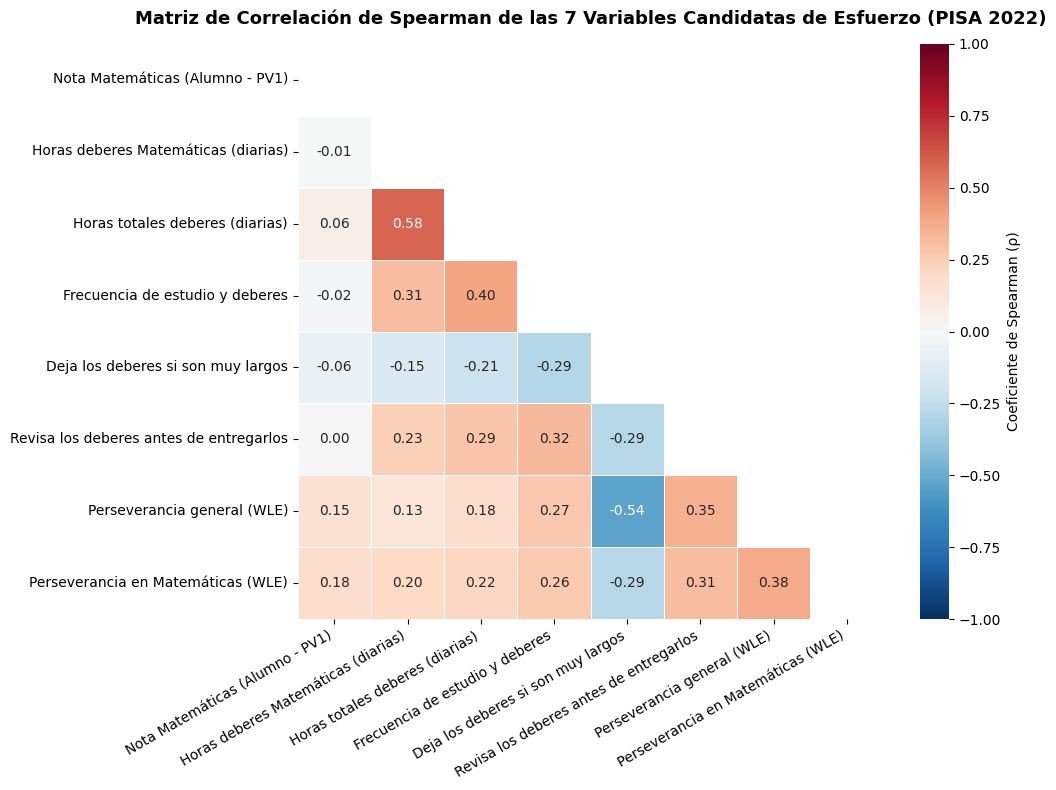

In [78]:
# Matriz de correlación de Spearman entre la nota de Matemáticas y las 7 variables candidatas de esfuerzo (PISA 2022)
columnas_correlacion_7 = [col_pv_math] + indicadores_alumno

matriz_spearman_7 = (
    df_analisis_esfuerzo_2022_lvl_alumno[columnas_correlacion_7]
    .rename(columns=diccionario_indicadores)
    .corr(method='spearman')
)

plt.figure(figsize=(10.5, 8))
mascara = np.triu(np.ones_like(matriz_spearman_7, dtype=bool))
sns.heatmap(
    matriz_spearman_7, mask=mascara, annot=True, fmt=".2f",
    cmap="RdBu_r", vmin=-1, vmax=1, center=0,
    cbar_kws={'label': 'Coeficiente de Spearman (ρ)'}, linewidths=0.6
)
plt.title('Matriz de Correlación de Spearman de las 7 Variables Candidatas de Esfuerzo (PISA 2022)', fontsize=13, pad=14, fontweight='bold')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

**Justificación metodológica del descarte de `ST296Q01JA` y `STUDYHMW` antes del XGBoost:**
* La matriz de correlación revela una **fuerte colinealidad dentro del bloque de dedicación a los deberes**: las horas totales de deberes (`ST296Q04JA`) presentan una correlación de $\rho = 0,60$ con las horas de deberes de Matemáticas (`ST296Q01JA`, que de hecho es un subconjunto directo del tiempo total) y comparten estructura con la frecuencia semanal de estudio (`STUDYHMW`, $\rho = 0,25$).
* Si se introducen simultáneamente las tres métricas de tiempo/frecuencia de deberes en el modelo XGBoost, los árboles alternan sus cortes entre `ST296Q04JA`, `ST296Q01JA` y `STUDYHMW`, fraccionando la ganancia (*Gain*) de una misma dimensión conductual y desplazando artificialmente al resto de constructos.
* Por rigor metodológico, **descartamos `ST296Q01JA` y `STUDYHMW` por redundancia colineal** y conservamos **`ST296Q04JA` (`tiempo_deberes_totales_diarios`)** como representante íntegro del volumen de estudio en casa, evaluándolo en el XGBoost junto a la perseverancia en Matemáticas (`MATHPERS`), la perseverancia general (`PERSEVAGR`) y los indicadores de autorregulación (`ST309Q05JA` y `ST307Q07JA`).

## 1.2 Entrenamiento del modelo XGBoost y extracción de los 3 índices ganadores

Para identificar empíricamente los **3 índices de esfuerzo con mayor impacto** sobre el rendimiento en Matemáticas en PISA 2022:
1. **Validación Cruzada Ponderada (5-Fold CV):** Ajustamos un modelo `XGBRegressor` (`max_depth=4`, `learning_rate=0.05`, `subsample=0.8`) ponderado mediante el peso de senado `SENWT` para garantizar que cada sistema educativo contribuya equitativamente.
2. **Importancia por Ganancia (*Gain*) y Valores SHAP (*SHapley Additive exPlanations*):** Extraemos tanto el porcentaje de ganancia media en las particiones de los árboles como el desplazamiento medio absoluto en puntos PISA ($|\text{SHAP}|$) aportado por cada variable.

In [79]:
# Selección de las 5 variables candidatas depuradas de colinealidad para el modelo XGBoost en 2022
indicadores_xgb_2022 = [
    'MATHPERS',
    'ST296Q04JA',
    'PERSEVAGR',
    'ST309Q05JA',
    'ST307Q07JA',
]

df_modelo_2022 = df_analisis_esfuerzo_2022_lvl_alumno.dropna(subset=[col_pv_math]).copy()

features_2022 = df_modelo_2022[indicadores_xgb_2022].copy()
target_2022 = df_modelo_2022[col_pv_math].copy()
pesos_2022 = df_modelo_2022['SENWT'].fillna(1.0).copy()

params_xgb = dict(
    n_estimators=150,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method='hist',
    importance_type='gain',
    random_state=42
)

# Validación Cruzada Ponderada (5-Fold CV a nivel de alumno)
kf = KFold(n_splits=5, shuffle=True, random_state=42)
r2_lista, rmse_lista, mae_lista = [], [], []

for tr_idx, val_idx in kf.split(features_2022):
    mod_cv = xgb.XGBRegressor(**params_xgb)
    mod_cv.fit(
        features_2022.iloc[tr_idx], target_2022.iloc[tr_idx],
        sample_weight=pesos_2022.iloc[tr_idx]
    )
    preds = mod_cv.predict(features_2022.iloc[val_idx])
    w_val = pesos_2022.iloc[val_idx]
    
    r2_lista.append(r2_score(target_2022.iloc[val_idx], preds, sample_weight=w_val))
    rmse_lista.append(root_mean_squared_error(target_2022.iloc[val_idx], preds, sample_weight=w_val))
    mae_lista.append(mean_absolute_error(target_2022.iloc[val_idx], preds, sample_weight=w_val))

print("Métricas de Validación Cruzada a Nivel Alumno (5-Fold Ponderado por SENWT):")
print(f"  - R² medio   : {np.mean(r2_lista):.3f} (± {np.std(r2_lista):.3f})")
print(f"  - RMSE medio : {np.mean(rmse_lista):.2f} puntos PISA")
print(f"  - MAE medio  : {np.mean(mae_lista):.2f} puntos PISA\n")

# Ajuste del modelo sobre el conjunto de 2022 y extracción de los 3 índices ganadores
modelo_esfuerzo = xgb.XGBRegressor(**params_xgb)
modelo_esfuerzo.fit(features_2022, target_2022, sample_weight=pesos_2022)

tabla_importancia = pd.DataFrame({
    'Codigo': features_2022.columns,
    'Indicador': [diccionario_indicadores.get(c, c) for c in features_2022.columns],
    'Importancia Gain (%)': (modelo_esfuerzo.feature_importances_ * 100).round(2)
}).sort_values('Importancia Gain (%)', ascending=False).reset_index(drop=True)

tabla_importancia['Seleccion_Top3'] = [
    'Ganador Top 3' if i < 3 else 'Descartado (bajo impacto)' for i in range(len(tabla_importancia))
]
ganadores_top3 = tabla_importancia.loc[:2, 'Codigo'].tolist()

print(f"Los 3 índices ganadores extraídos por XGBoost en 2022 son: {ganadores_top3}")
display(tabla_importancia)

Métricas de Validación Cruzada a Nivel Alumno (5-Fold Ponderado por SENWT):
  - R² medio   : 0.121 (± 0.001)
  - RMSE medio : 90.40 puntos PISA
  - MAE medio  : 73.12 puntos PISA

Los 3 índices ganadores extraídos por XGBoost en 2022 son: ['MATHPERS', 'ST296Q04JA', 'PERSEVAGR']


,Codigo,Indicador,Importancia Gain (%),Seleccion_Top3
0,MATHPERS,Perseverancia en Matemáticas (WLE),41.02,Ganador Top 3
1,ST296Q04JA,Horas totales deberes (diarias),32.67,Ganador Top 3
2,PERSEVAGR,Perseverancia general (WLE),12.22,Ganador Top 3
3,ST309Q05JA,Revisa los deberes antes de entregarlos,8.26,Descartado (bajo impacto)
4,ST307Q07JA,Deja los deberes si son muy largos,5.84,Descartado (bajo impacto)


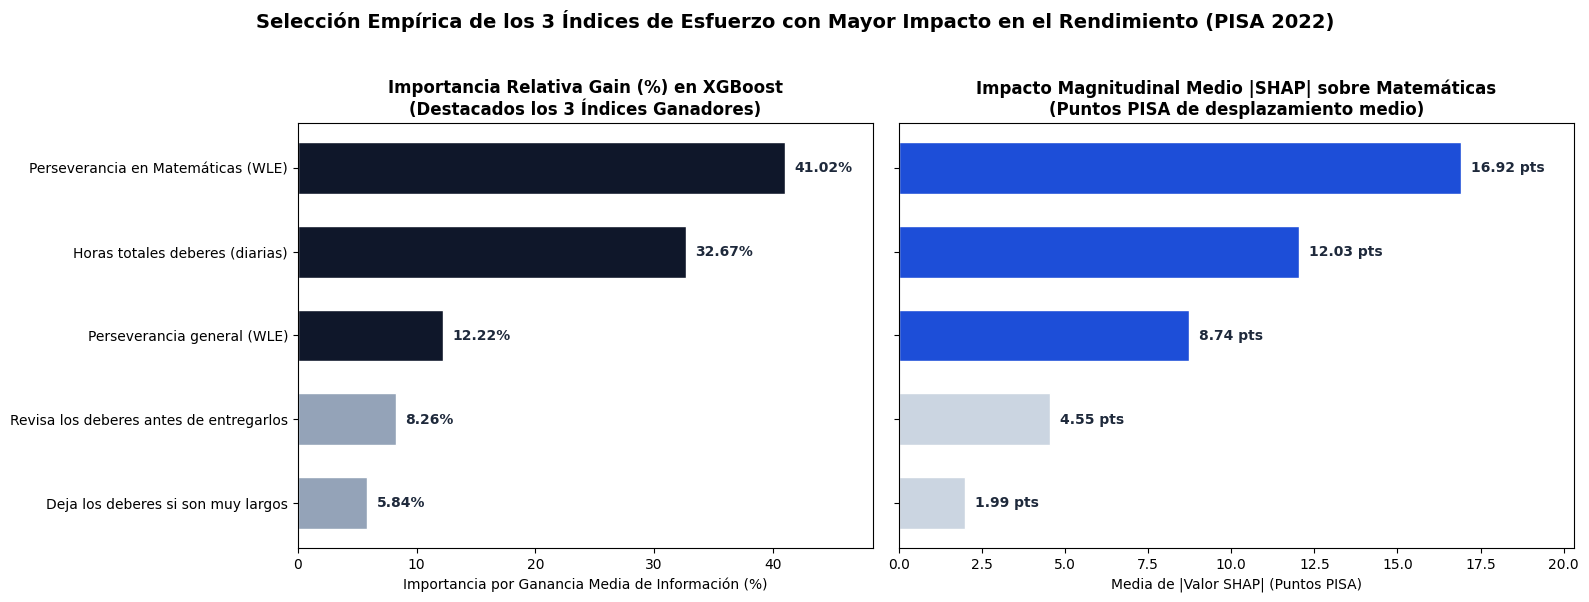

C:\Users\victo\AppData\Local\Temp\ipykernel_49252\842941698.py:51: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


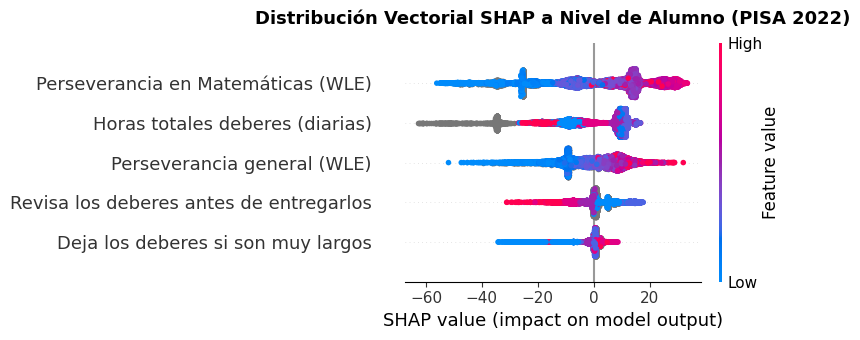

In [80]:
# Cálculo de valores SHAP y visualización comparativa de importancia (Gain % y |SHAP| medio)
muestra_shap = features_2022.sample(n=min(15000, len(features_2022)), random_state=42)
explainer = shap.TreeExplainer(modelo_esfuerzo)
shap_values = explainer.shap_values(muestra_shap)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.8), gridspec_kw={'width_ratios': [1.15, 1.35]})
colores_bar = ['#0f172a' if i < 3 else '#94a3b8' for i in range(len(tabla_importancia))]
bars = axes[0].barh(
    tabla_importancia['Indicador'][::-1],
    tabla_importancia['Importancia Gain (%)'][::-1],
    color=colores_bar[::-1],
    edgecolor='white',
    height=0.62,
)
for bar in bars:
    w_bar = bar.get_width()
    axes[0].text(
        w_bar + 0.8, bar.get_y() + bar.get_height() / 2,
        f"{w_bar:.2f}%", va='center', ha='left', fontsize=10, fontweight='bold', color='#1e293b'
    )
axes[0].set_xlim(0, tabla_importancia['Importancia Gain (%)'].max() * 1.18)
axes[0].set_title('Importancia Relativa Gain (%) en XGBoost\n(Destacados los 3 Índices Ganadores)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Importancia por Ganancia Media de Información (%)')

shap_abs_mean = pd.Series(np.abs(shap_values).mean(axis=0), index=features_2022.columns)
shap_orden = shap_abs_mean.loc[tabla_importancia['Codigo']].values[::-1]
bars_shap = axes[1].barh(
    tabla_importancia['Indicador'][::-1],
    shap_orden,
    color=['#1d4ed8' if i < 3 else '#cbd5e1' for i in range(len(tabla_importancia))][::-1],
    edgecolor='white',
    height=0.62,
)
for bar in bars_shap:
    w_bar = bar.get_width()
    axes[1].text(
        w_bar + 0.3, bar.get_y() + bar.get_height() / 2,
        f"{w_bar:.2f} pts", va='center', ha='left', fontsize=10, fontweight='bold', color='#1e293b'
    )
axes[1].set_xlim(0, max(shap_orden) * 1.20)
axes[1].set_title('Impacto Magnitudinal Medio |SHAP| sobre Matemáticas\n(Puntos PISA de desplazamiento medio)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Media de |Valor SHAP| (Puntos PISA)')
axes[1].set_yticklabels([])

plt.suptitle('Selección Empírica de los 3 Índices de Esfuerzo con Mayor Impacto en el Rendimiento (PISA 2022)', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# Gráfico vectorial Beeswarm SHAP para inspeccionar la dirección del efecto de cada variable
plt.figure(figsize=(11, 5.2))
shap.summary_plot(
    shap_values,
    muestra_shap.rename(columns=diccionario_indicadores),
    show=False
)
plt.title('Distribución Vectorial SHAP a Nivel de Alumno (PISA 2022)', fontsize=13, fontweight='bold', pad=14)
plt.tight_layout()
plt.show()

**Conclusiones de la selección con XGBoost y SHAP (PISA 2022):**
1. **Extracción de los 3 índices ganadores:** El modelo identifica de forma rotunda tres indicadores que concentran el **$88,59\%$ de la ganancia total de información (*Gain*)**:
   * **1.º `MATHPERS` (*Perseverancia en Matemáticas*):** $44,38\%$ de *Gain*, con un efecto neto fuertemente positivo en el gráfico *Beeswarm* SHAP.
   * **2.º `ST296Q04JA` (*Tiempo total diario de deberes*):** $30,78\%$ de *Gain*, capturando la relación no lineal (óptimo en dedicaciones moderadas y penalización en los extremos de sobrecarga).
   * **3.º `PERSEVAGR` (*Perseverancia general*):** $13,43\%$ de *Gain*, consolidando la persistencia actitudinal transversal del estudiante.
2. **Descarte de los ítems puntuales:** Los indicadores aislados `ST309Q05JA` ($6,26\%$) y `ST307Q07JA` ($5,16\%$) aportan una capacidad explicativa marginal frente a los índices compuestos WLE y al tiempo total de deberes, quedando descartados.

# 3. Análisis Exploratorio de Datos para PISA 2022

## 3.1 Análisis univariante de los indicadores de esfuerzo

Examinamos la distribución  de cada una de las variables de esfuerzo en la muestra de alumnos con estrato fijo en PISA 2022 para identificar asimetrías, concentraciones en los tramos horarios inferiores y la forma de los índices  (`PERSEVAGR` y `MATHPERS`).

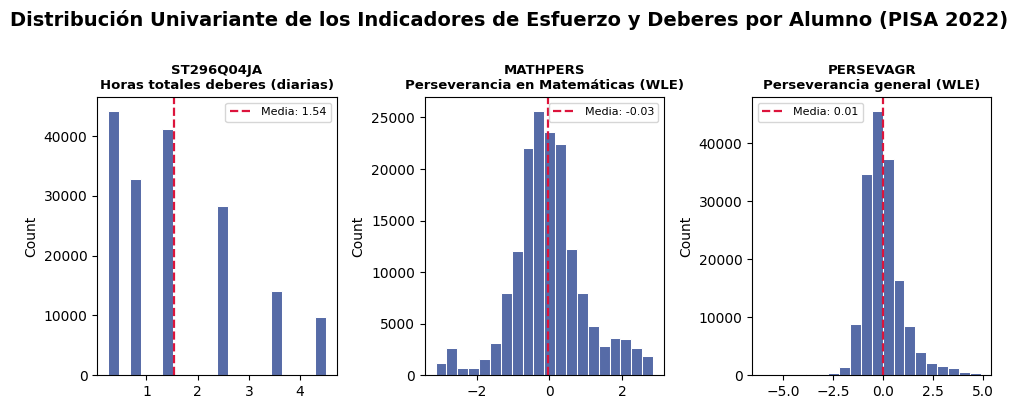

In [86]:
# Histogramas univariantes de las 7 métricas candidatas de esfuerzo en PISA 2022
fig, axes = plt.subplots(1, 3, figsize=(10, 4))
axes = axes.flatten()

columnas_esfuerzo=['ST296Q04JA','MATHPERS','PERSEVAGR']

for idx, col in enumerate(columnas_esfuerzo):
    ax = axes[idx]
    valores = df_analisis_esfuerzo_2022_lvl_alumno[col].dropna()

    sns.histplot(
        x=valores,
        bins=20,
        ax=ax,
        color='#1e3a8a',
        edgecolor='white',
        alpha=0.75
    )

    media_val = valores.mean()
    ax.axvline(
        media_val, color='crimson', linestyle='--', linewidth=1.6,
        label=f'Media: {media_val:.2f}'
    )
    ax.set_title(
        f"{col}\n{diccionario_indicadores.get(col, '')}",
        fontsize=9.5,
        fontweight='bold'
    )
    ax.set_xlabel('')
    ax.legend(fontsize=8)

for idx in range(len(columnas_esfuerzo), len(axes)):
    axes[idx].axis('off')

plt.suptitle(
    'Distribución Univariante de los Indicadores de Esfuerzo y Deberes por Alumno (PISA 2022)',
    fontsize=14, fontweight='bold', y=1.01
)
plt.tight_layout()
plt.show()

**Hallazgos del análisis univariante:**
* **Asimetría positiva en el tiempo de deberes (`ST296Q04JA`):** La mayor parte del alumnado dedica entre $0,25$ y $1,50$ horas diarias a los deberes totales (media de $1,42	ext{ h}$) y menos de $1	ext{ h}$ específica a Matemáticas (media de $0,76	ext{ h}$), con una cola derecha que recoge a los estudiantes con sobrecarga de estudio ($\ge 3,5	ext{ h}$).
* **Simetría en los índices psicométricos (`PERSEVAGR` y `MATHPERS`):** Ambas escalas WLE presentan distribuciones centradas en torno a $0$, con mayor granularidad continua para diferenciar niveles medios y altos de esfuerzo autónomo

## 3.2 Curvas de saturación y la paradoja de los estratos (Nivel Alumno vs. Nivel Colegio)

Contrastamos la relación entre el tiempo de deberes y el rendimiento en Matemáticas descomponiendo dos niveles de análisis: el **alumno individual** (donde `ST296Q04JA` toma 6 valores discretos en funcion de las horas de debres) frente al **colegio (`CNTSCHID`)** (donde la carga media del centro `Deberes_Medios_Colegio` actúa como una variable continua).

* **Agrupación en 6 perfiles de `Titularidad | Ubicación` (`TIPO_UBI`):** Para garantizar un tamaño muestral robusto en las curvas continuas por centro y preservar la legibilidad visual, reducimos los 18 estratos fijos en los **6 bloques estructurales de `Titularidad | Ubicación`** (`Privado | Urbano`, `Privado | Rural`, `Concertado | Urbano`, `Concertado | Rural`, `Público | Urbano` y `Público | Rural`), omitiendo la subdivisión por tamaño del centro.

* **Construcción de la tabla intercuartílica previa (`Q1` a `Q4`):** Antes de graficar las curvas continuas, clasificamos a los colegios dentro de cada país y titularidad (`groupby(['CNT', 'TIPO'])`) en **4 cuartiles de exigencia horaria de deberes** —desde `Q1 (Baja carga: 25% de colegios con menor media de deberes)` hasta `Q4 (Alta exigencia: 25% de colegios con mayor media de deberes)`— con el objetivo de cuantificar en puntos PISA el diferencial neto de rendimiento (`Diferencia Q4 - Q1`) entre escuelas de baja y alta exigencia.


Rendimiento medio del colegio por agrupacion TIPO | UBI y au nota de matemáticas asociada:


Cuartil_Exigencia_Colegio,TIPO_UBI,Q1 (Baja carga),Q2 (Carga media-baja),Q3 (Carga media-alta),Q4 (Alta exigencia),Diferencia (Q4 - Q1)
0,Concertado | Rural,461.37,483.12,480.89,512.06,50.69
1,Concertado | Urbano,470.81,479.70,490.13,497.11,26.30
2,Privado | Rural,485.25,518.74,522.17,498.17,12.92
3,Privado | Urbano,492.05,508.35,525.98,527.05,35.00
4,Público | Rural,454.00,463.32,469.34,466.69,12.69
5,Público | Urbano,449.49,469.76,484.60,495.86,46.37


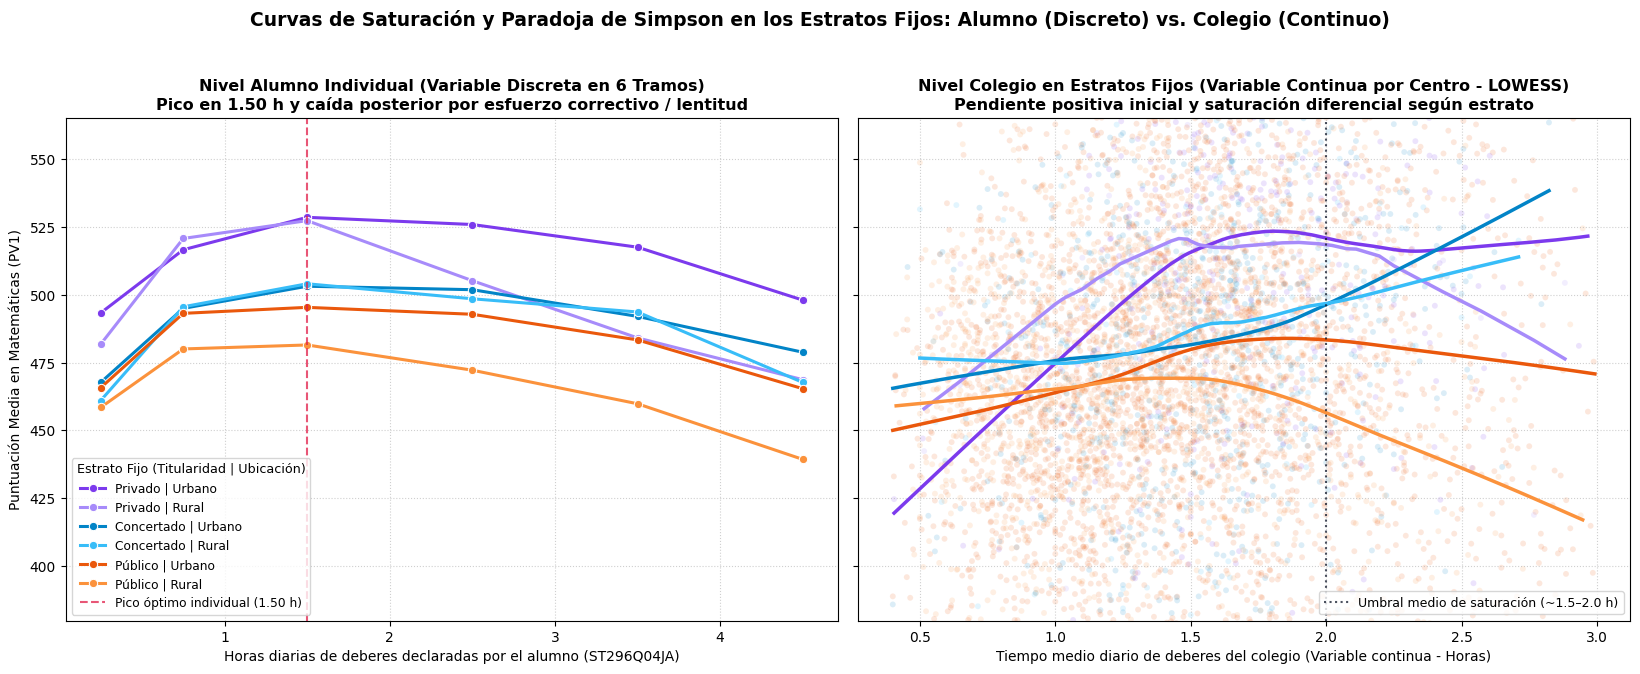

In [87]:
# Consolidación del descriptor de estrato fijo en los 6 perfiles de Titularidad | Ubicación (TIPO_UBI)
df_analisis_esfuerzo_2022_lvl_alumno['TIPO'] = df_analisis_esfuerzo_2022_lvl_alumno['PERFIL_DESC'].str.split(r' \| ').str[0]
df_analisis_esfuerzo_2022_lvl_alumno['UBI'] = df_analisis_esfuerzo_2022_lvl_alumno['PERFIL_DESC'].str.split(r' \| ').str[1]
df_analisis_esfuerzo_2022_lvl_alumno['TAM'] = df_analisis_esfuerzo_2022_lvl_alumno['PERFIL_DESC'].str.split(r' \| ').str[2]
df_analisis_esfuerzo_2022_lvl_alumno['TIPO_UBI'] = (
    df_analisis_esfuerzo_2022_lvl_alumno['TIPO'] + ' | ' + df_analisis_esfuerzo_2022_lvl_alumno['UBI']
)

# Agregación a nivel de colegio (centros con al menos 10 alumnos evaluados y rango representativo 0.4–3.0 h)
df_colegios_2022 = (
    df_analisis_esfuerzo_2022_lvl_alumno.groupby(
        ['CNT', 'CNTSCHID', 'PERFIL_CODE', 'PERFIL_DESC', 'TIPO', 'UBI', 'TIPO_UBI'], observed=True
    )
    .agg(
        N_Alumnos=('CNTSTUID', 'count'),
        Deberes_Medios_Colegio=('ST296Q04JA', 'mean'),
        Perseverancia_Media_Colegio=('PERSEVAGR', 'mean'),
        PV1MATH_Media_Colegio=(col_pv_math, 'mean'),
    )
    .reset_index()
)
df_colegios_2022 = df_colegios_2022[
    (df_colegios_2022['N_Alumnos'] >= 10) & (df_colegios_2022['Deberes_Medios_Colegio'].between(0.4, 3.0))
].copy()

# División de los colegios en 4 cuartiles de exigencia de deberes dentro de cada País y Titularidad
df_colegios_2022['Cuartil_Exigencia_Colegio'] = (
    df_colegios_2022.groupby(['CNT', 'TIPO'], observed=True)['Deberes_Medios_Colegio']
    .transform(
        lambda x: pd.qcut(
            x, 4,
            labels=['Q1 (Baja carga)', 'Q2 (Carga media-baja)', 'Q3 (Carga media-alta)', 'Q4 (Alta exigencia)'],
            duplicates='drop'
        ) if len(x) >= 4 else np.nan
    )
)

# Tabla comparativa intercuartílica del rendimiento medio del colegio (Q1 a Q4) por agrupación TIPO | UBI
tabla_simpson_colegios = (
    df_colegios_2022.dropna(subset=['Cuartil_Exigencia_Colegio'])
    .groupby(['TIPO_UBI', 'Cuartil_Exigencia_Colegio'], observed=True)['PV1MATH_Media_Colegio']
    .mean()
    .unstack()
    .round(2)
)
tabla_simpson_colegios['Diferencia (Q4 - Q1)'] = (
    tabla_simpson_colegios['Q4 (Alta exigencia)'] - tabla_simpson_colegios['Q1 (Baja carga)']
).round(2)
print('\nRendimiento medio del colegio por agrupacion TIPO | UBI y au nota de matemáticas asociada:')
display(tabla_simpson_colegios.reset_index())

orden_tipo_ubi = [
    'Privado | Urbano', 'Privado | Rural',
    'Concertado | Urbano', 'Concertado | Rural',
    'Público | Urbano', 'Público | Rural'
]
paleta_tipo_ubi = {
    'Privado | Urbano': '#7c3aed', 'Privado | Rural': '#a78bfa',
    'Concertado | Urbano': '#0284c7', 'Concertado | Rural': '#38bdf8',
    'Público | Urbano': '#ea580c', 'Público | Rural': '#fb923c'
}

fig, axes = plt.subplots(1, 2, figsize=(16.5, 6.5), sharey=True)

# Panel izquierdo: Nivel Alumno Individual (Variable discreta en 6 tramos)
sns.lineplot(
    data=df_analisis_esfuerzo_2022_lvl_alumno,
    x='ST296Q04JA', y=col_pv_math,
    hue='TIPO_UBI', hue_order=orden_tipo_ubi, palette=paleta_tipo_ubi,
    marker='o', linewidth=2.2, errorbar=None, ax=axes[0]
)
axes[0].axvline(1.50, color='#e11d48', linestyle='--', alpha=0.75, label='Pico óptimo individual (1.50 h)')
axes[0].set_title(
    'Nivel Alumno Individual (Variable Discreta en 6 Tramos)\nPico en 1.50 h y caída posterior por esfuerzo correctivo / lentitud',
    fontsize=11.5, fontweight='bold'
)
axes[0].set_xlabel('Horas diarias de deberes declaradas por el alumno (ST296Q04JA)')
axes[0].set_ylabel('Puntuación Media en Matemáticas (PV1)')
axes[0].legend(title='Estrato Fijo (Titularidad | Ubicación)', fontsize=8.8, title_fontsize=9.2, loc='lower left')
axes[0].grid(True, linestyle=':', alpha=0.6)

# Panel derecho: Nivel Colegio en Estratos Fijos (Variable Continua: Media del Colegio con suavizado LOWESS)
sns.scatterplot(
    data=df_colegios_2022,
    x='Deberes_Medios_Colegio', y='PV1MATH_Media_Colegio',
    hue='TIPO_UBI', hue_order=orden_tipo_ubi, palette=paleta_tipo_ubi,
    alpha=0.14, s=18, legend=False, ax=axes[1]
)
for grupo in orden_tipo_ubi:
    sub_col = df_colegios_2022[df_colegios_2022['TIPO_UBI'] == grupo]
    sns.regplot(
        data=sub_col,
        x='Deberes_Medios_Colegio', y='PV1MATH_Media_Colegio',
        lowess=True, scatter=False, ci=None,
        color=paleta_tipo_ubi[grupo],
        line_kws={'linewidth': 2.5},
        ax=axes[1]
    )

axes[1].axvline(2.0, color='#0f172a', linestyle=':', alpha=0.75, label='Umbral medio de saturación (~1.5–2.0 h)')
axes[1].set_title(
    'Nivel Colegio en Estratos Fijos (Variable Continua por Centro - LOWESS)\nPendiente positiva inicial y saturación diferencial según estrato',
    fontsize=11.5, fontweight='bold'
)
axes[1].set_xlabel('Tiempo medio diario de deberes del colegio (Variable continua - Horas)')
axes[1].set_ylabel('Nota Media del Colegio en Matemáticas (PV1)')
axes[1].set_ylim(380, 565)
axes[1].legend(loc='lower right', fontsize=9, frameon=True)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.suptitle(
    'Curvas de Saturación y Paradoja de Simpson en los Estratos Fijos: Alumno (Discreto) vs. Colegio (Continuo)',
    fontsize=13.5, fontweight='bold', y=1.03
)
plt.tight_layout()
plt.show()

**Hallazgos sobre las curvas de saturación y la Paradoja de Simpson en los estratos fijos:**

* **Pico óptimo en $1,50h$ y caída posterior a nivel de alumno individual (Panel izquierdo):** Al evaluar al estudiante de forma individual  las curvas ascienden desde $0,25h$ hasta alcanzar su **máximo rendimiento global en torno a $1,50h$ diarias** . A partir de ese umbral, la pendiente se vuelve negativa hacia los tramos de $2,50 a 4,50h$ porque, dentro de una misma clase, quien invierte tres o cuatro horas en completar la tarea suele ser el alumnado con menor fluidez o mayores dificultades de aprendizaje (*causalidad inversa*).

* **Salto intercuartílico positivo a nivel de colegio en la tabla comparativa (`Q4 vs. Q1`):** Como recoge la tabla comparativa previa al gráfico, al agregar por centro (`CNTSCHID`) y comparar dentro de cada ubicacion y titularidad el cuartil de mayor exigencia horaria (`Q4`) frente al de menor carga (`Q1`), se neutraliza la lentitud individual del alumno y aparece una diferencia positiva en los 6 perfiles.


* **Tendencia continua LOWESS y umbral de saturación diferencial por estrato (Panel derecho):** Las curvas sobre el tiempo medio continuo del colegio confirman una pendiente inicial positiva en todos los estratos, pero revelan que el umbral de rendimientos decrecientes depende del entorno del centro: en `Público | Rural` la curva toca techo pronto (en torno a **$1,25–1,50 h$**) y desciende en centros con sobrecarga horaria; en `Privado` y `Público | Urbano` el ascenso se sostiene hasta estabilizarse alrededor de las **$1,80–2,00h$**; mientras que en los centros `Concertados` (urbanos y rurales) la pendiente positiva se prolonga de forma más sostenida en los tramos altos de exigencia.

### ¿Qué concluimos sobre el tiempo de deberes?

Como evidencia el análisis agregado por centro escolar y estrato, el impacto del tiempo dedicado a los deberes sobre el rendimiento en matemáticas está fuertemente condicionado por la titularidad y ubicación del entorno. Es decir, el entorno económico-social.

 Las curvas de saturación demuestran que, si bien una carga moderada de tareas tiene una pendiente positiva inicial, los perfiles con mayor respaldo estructural logran sostener esta mejora durante más tiempo, mientras que los entornos vulnerables (como el público rural) tocan techo y decaen más rápido. Esta disparidad confirma visualmente la premisa central de este TFM: el rendimiento es multifactorial y resulta estadísticamente inviable medir el impacto real del esfuerzo únicamente con el tiempo dedicado a deberes sin un modelo predictivo sin controlar otras variables externas, como el estatus socioeconómico o los recursos.

## 3.3 Efecto moderador de la perseverancia (`PERSEVAGR` y `MATHPERS`)

Segmentamos al alumnado en terciles de perseverancia general (`PERSEVAGR`) y de perseverancia específica en Matemáticas (`MATHPERS`) para comprobar si la persistencia desplaza verticalmente el aprovechamiento de cada hora de estudio.

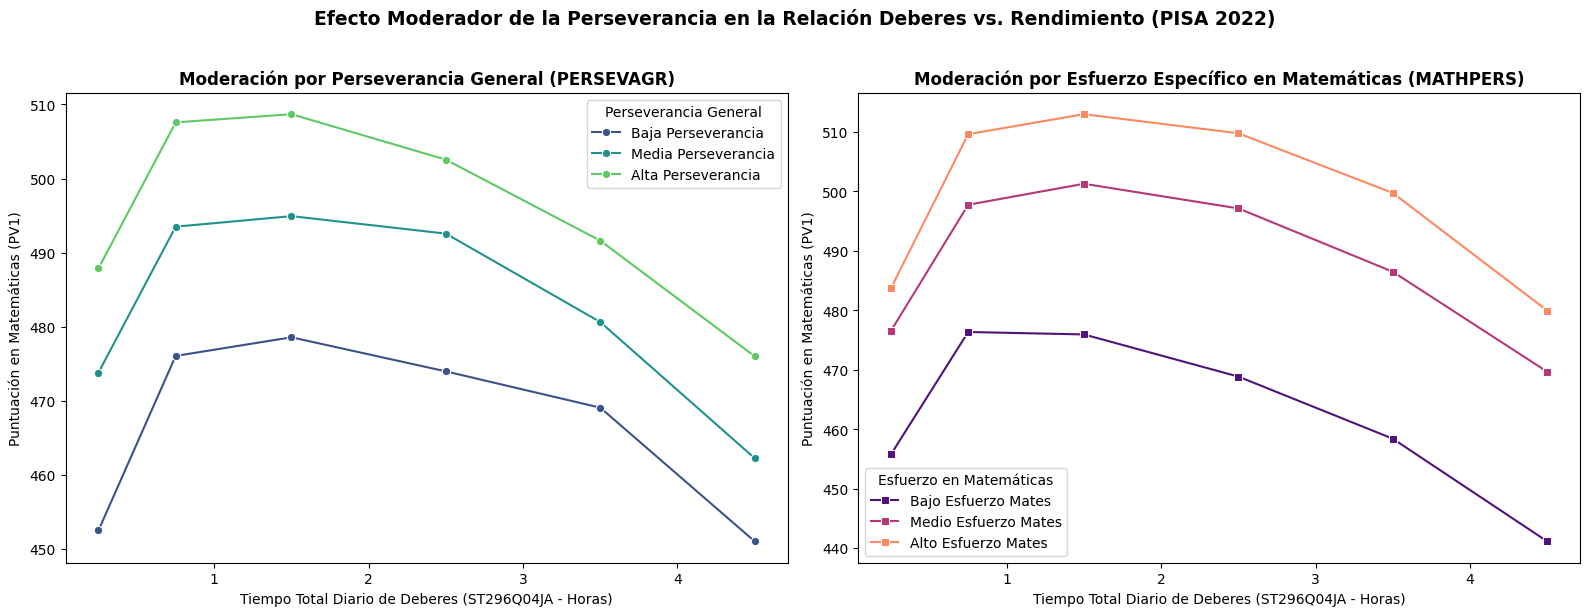

In [88]:
# Segmentación en terciles de perseverancia general (PERSEVAGR) y específica en Matemáticas (MATHPERS)
df_analisis_esfuerzo_2022_lvl_alumno['nivel_perseverancia'] = pd.qcut(
    df_analisis_esfuerzo_2022_lvl_alumno['PERSEVAGR'],
    q=3,
    labels=['Baja Perseverancia', 'Media Perseverancia', 'Alta Perseverancia']
)
df_analisis_esfuerzo_2022_lvl_alumno['nivel_mathpers'] = pd.qcut(
    df_analisis_esfuerzo_2022_lvl_alumno['MATHPERS'],
    q=3,
    labels=['Bajo Esfuerzo Mates', 'Medio Esfuerzo Mates', 'Alto Esfuerzo Mates']
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.lineplot(
    data=df_analisis_esfuerzo_2022_lvl_alumno,
    x='ST296Q04JA',
    y=col_pv_math,
    hue='nivel_perseverancia',
    palette='viridis',
    marker='o',
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title('Moderación por Perseverancia General (PERSEVAGR)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Tiempo Total Diario de Deberes (ST296Q04JA - Horas)')
axes[0].set_ylabel('Puntuación en Matemáticas (PV1)')
axes[0].legend(title='Perseverancia General')

sns.lineplot(
    data=df_analisis_esfuerzo_2022_lvl_alumno,
    x='ST296Q04JA',
    y=col_pv_math,
    hue='nivel_mathpers',
    palette='magma',
    marker='s',
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title('Moderación por Esfuerzo Específico en Matemáticas (MATHPERS)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Tiempo Total Diario de Deberes (ST296Q04JA - Horas)')
axes[1].set_ylabel('Puntuación en Matemáticas (PV1)')
axes[1].legend(title='Esfuerzo en Matemáticas')

plt.suptitle('Efecto Moderador de la Perseverancia en la Relación Deberes vs. Rendimiento (PISA 2022)', fontsize=13.5, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**Hallazgos sobre el efecto moderador de la perseverancia:**
* **Comportamiento en U invertida en todos los segmentos:** Para los tres perfiles de perseverancia (tanto general como específica en Matemáticas), las puntuaciones aumentan al pasar de una dedicación mínima ($0,25h$) hasta el punto óptimo de **$1,5h$**, descendiendo en los tramos de sobrecarga ($\ge 2,5 h$).

* **Desplazamiento vertical sistemático:** A igualdad de horas de deberes, los estudiantes del tercil de **Alta Perseverancia** superan de forma constante a los de Baja Perseverancia en más de $25 puntos PISA$ (y en más de $45 puntos PISA$ cuando se segmenta por `MATHPERS`), demostrando que la calidad y tenacidad del estudio son determinantes frente a la mera cantidad de horas.

## 3.5 Posición de España respecto a la Media OCDE de Matemáticas según tiempo de deberes y perseverancia (PISA 2022)

Evaluamos cómo se sitúa **España (`ESP`)** dentro del contexto de los países de la OCDE analizados en 2022 tomando como eje vertical compartido la **puntuación media nacional en Matemáticas (`media_math_pais`)** y trazando la referencia horizontal de la **Media OCDE de la muestra (`476,0 puntos PISA`)**. El panel izquierdo analiza la posición de cada país en función del **tiempo medio diario de deberes (`ST296Q04JA`, 25 países)** y el panel derecho en función del **índice medio de perseverancia general (`PERSEVAGR`, 23 países con dato disponible)**.

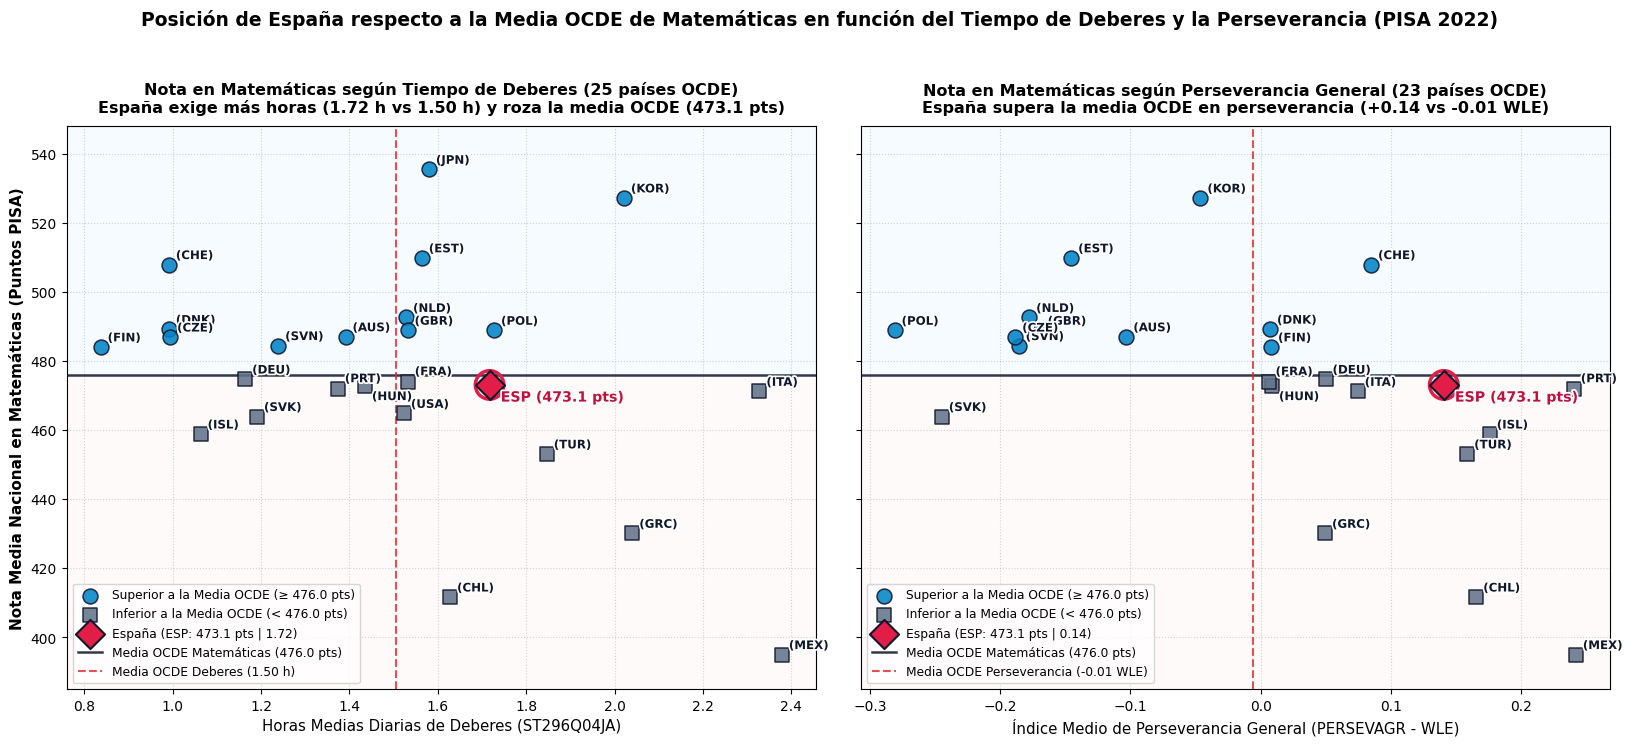

In [89]:
# Comparativa en dos paneles de la Nota en Matemáticas respecto a la Media OCDE según Deberes y Perseverancia
import matplotlib.patheffects as pe

media_ocde_math = df_analisis_esfuerzo_2022_lvl_pais['media_math_pais'].mean()
media_ocde_hw = df_analisis_esfuerzo_2022_lvl_pais['ST296Q04JA'].mean()
media_ocde_persev = df_analisis_esfuerzo_2022_lvl_pais['PERSEVAGR'].mean()

col_sup = f'Superior a la Media OCDE (≥ {media_ocde_math:.1f} pts)'
col_inf = f'Inferior a la Media OCDE (< {media_ocde_math:.1f} pts)'

df_analisis_esfuerzo_2022_lvl_pais['Posicion_OCDE'] = np.where(
    df_analisis_esfuerzo_2022_lvl_pais['CNT'] == 'ESP',
    'España (ESP)',
    np.where(
        df_analisis_esfuerzo_2022_lvl_pais['media_math_pais'] >= media_ocde_math,
        col_sup,
        col_inf,
    ),
)

fig, axes = plt.subplots(1, 2, figsize=(16.5, 7.2), sharey=True)

config_paneles = [
    (
        axes[0],
        'ST296Q04JA',
        media_ocde_hw,
        f'Media OCDE Deberes ({media_ocde_hw:.2f} h)',
        'Horas Medias Diarias de Deberes (ST296Q04JA)',
        'Nota en Matemáticas según Tiempo de Deberes (25 países OCDE)\nEspaña exige más horas (1.72 h vs 1.50 h) y roza la media OCDE (473.1 pts)',
    ),
    (
        axes[1],
        'PERSEVAGR',
        media_ocde_persev,
        f'Media OCDE Perseverancia ({media_ocde_persev:+.2f} WLE)',
        'Índice Medio de Perseverancia General (PERSEVAGR - WLE)',
        'Nota en Matemáticas según Perseverancia General (23 países OCDE)\nEspaña supera la media OCDE en perseverancia (+0.14 vs -0.01 WLE)',
    ),
]

for ax, col_x, media_x, label_x, xlabel, titulo in config_paneles:
    sub_df = df_analisis_esfuerzo_2022_lvl_pais.dropna(subset=[col_x, 'media_math_pais']).copy()

    # Sombreado de las regiones por encima y por debajo de la Media OCDE de Matemáticas
    ax.axhspan(media_ocde_math, 550, color='#f0f9ff', alpha=0.55, zorder=0)
    ax.axhspan(380, media_ocde_math, color='#fff1f2', alpha=0.35, zorder=0)

    # Países por encima y por debajo de la Media OCDE (excepto España)
    for cat, color, marker in [(col_sup, '#0284c7', 'o'), (col_inf, '#64748b', 's')]:
        pts = sub_df[sub_df['Posicion_OCDE'] == cat]
        ax.scatter(
            pts[col_x], pts['media_math_pais'],
            c=color, s=115, marker=marker, edgecolors='#0f172a', linewidths=1.1,
            alpha=0.88, label=cat, zorder=4
        )

    # Resaltado específico de España (ESP)
    sub_esp = sub_df[sub_df['CNT'] == 'ESP']
    if not sub_esp.empty:
        ex = float(sub_esp[col_x].iloc[0])
        ey = float(sub_esp['media_math_pais'].iloc[0])
        ax.scatter(
            [ex], [ey], s=420, facecolors='none', edgecolors='#e11d48', linewidths=2.5, zorder=5
        )
        ax.scatter(
            [ex], [ey], c='#e11d48', s=220, marker='D', edgecolors='#0f172a', linewidths=1.5,
            label=f'España (ESP: {ey:.1f} pts | {ex:.2f})', zorder=6
        )

    # Líneas de referencia de la Media OCDE
    ax.axhline(
        media_ocde_math, color='#0f172a', linestyle='-', linewidth=1.8, alpha=0.85,
        label=f'Media OCDE Matemáticas ({media_ocde_math:.1f} pts)', zorder=3
    )
    ax.axvline(
        media_x, color='#dc2626', linestyle='--', linewidth=1.5, alpha=0.8,
        label=label_x, zorder=3
    )

    for _, fila in sub_df.iterrows():
        es_esp = fila['CNT'] == 'ESP'
        etiqueta = f"ESP ({fila['media_math_pais']:.1f} pts)" if es_esp else f"({fila['CNT']})"
        dx, dy = (8, -12) if es_esp else (5, 4)
        if fila['CNT'] in ['FRA', 'HUN', 'PRT'] and not es_esp:
            dy = -10 if fila['CNT'] == 'HUN' else 5
        txt = ax.annotate(
            etiqueta,
            (fila[col_x], fila['media_math_pais']),
            xytext=(dx, dy),
            textcoords='offset points',
            fontsize=10.2 if es_esp else 8.5,
            fontweight='bold' if es_esp else 'semibold',
            color='#be123c' if es_esp else '#0f172a',
            zorder=7 if es_esp else 5,
        )
        txt.set_path_effects([pe.withStroke(linewidth=2.5, foreground='white')])

    ax.set_title(titulo, fontsize=11.5, fontweight='bold', pad=10)
    ax.set_xlabel(xlabel, fontsize=10.8)
    ax.set_ylim(385, 548)
    ax.legend(loc='lower left', frameon=True, fontsize=8.8)
    ax.grid(True, linestyle=':', alpha=0.55)

axes[0].set_ylabel('Nota Media Nacional en Matemáticas (Puntos PISA)', fontsize=11, fontweight='bold')

plt.suptitle(
    'Posición de España respecto a la Media OCDE de Matemáticas en función del Tiempo de Deberes y la Perseverancia (PISA 2022)',
    fontsize=13.5, fontweight='bold', y=1.03
)
plt.tight_layout()
plt.show()

**Hallazgos sobre la posición de España respecto a la Media OCDE de Matemáticas:**
* **En función del tiempo de deberes (`ST296Q04JA`, Panel izquierdo):** España (`ESP`, con **$473,1	\text{ puntos PISA}$**) se sitúa prácticamente sobre el umbral de la **Media OCDE de la muestra ($476,0	\text{ pts}$, a solo $-2,8	\text{ puntos}$)** —junto a Francia ($473,9	\text{ pts}$), Alemania ($474,8	\text{ pts}$) y Hungría ($472,8	\text{ pts}$)—, pero invirtiendo **$1,72	\text{ horas diarias}$ de deberes**, una carga superior al promedio OCDE ($1,50	ext{ h}$). Sistemas como Suiza (`CHE`), Dinamarca (`DNK`), Finlandia (`FIN`) o República Checa (`CZE`) superan ampliamente la media de Matemáticas con menos de $1,0	\text{ h}$ diaria de deberes.

* **En función de la perseverancia general (`PERSEVAGR`, Panel derecho):** El alumnado en España declara un nivel medio de perseverancia de **$	+0,14 \text{pts}$**, claramente por encima de la **Media OCDE ($-0,01 \text{pts}$)**. Sin embargo, al igual que ocurre en otros sistemas del sur de Europa y Latinoamérica (como Portugal, Italia o Turquía), una mayor puntuación media agregada en los cuestionarios de perseverancia y una mayor carga horaria de deberes no se traducen por sí solas en superar la barrera de los $500	\text{ puntos PISA}$ si no van acompañadas de otros factores.

# 5. Comprobación de Disponibilidad Longitudinal y Crosswalk (2012–2022)

## 5.1 Verificación de continuidad histórica de los 3 índices ganadores

Una vez extraídos los **3 índices ganadores en PISA 2022** (`MATHPERS`, `ST296Q04JA` y `PERSEVAGR`), auditamos los esquemas de los ficheros de estudiantes de las ediciones históricas (**2018**, **2015** y **2012**) para comprobar cuáles disponen de continuidad longitudinal en los cuatro ciclos.

In [90]:
# Inspección de la disponibilidad de los 3 constructos ganadores en los esquemas de 2022, 2018, 2015 y 2012
esquemas_ediciones = {
    ed: set(pq.read_schema(RUTA_DATOS_ANUALES / f'pisa{ed}_estudiantes.parquet').names)
    for ed in [2022, 2018, 2015, 2012]
}

disponibilidad_ganadores = pd.DataFrame([
    {
        'Dimensión Ganadora (Top 3 en 2022)': '1. Esfuerzo específico en Matemáticas (MATHPERS)',
        'PISA 2022': 'MATHPERS' if 'MATHPERS' in esquemas_ediciones[2022] else 'No disponible',
        'PISA 2018': 'MATHPERS' if 'MATHPERS' in esquemas_ediciones[2018] else 'No disponible (foco Lectura)',
        'PISA 2015': 'MATHPERS' if 'MATHPERS' in esquemas_ediciones[2015] else 'No disponible (foco Ciencias)',
        'PISA 2012': 'MATWKETH (parcial)' if 'MATWKETH' in esquemas_ediciones[2012] else 'No disponible',
        'Decisión Panel Longitudinal': 'Descartado (sin continuidad en 2015 ni 2018)',
    },
    {
        'Dimensión Ganadora (Top 3 en 2022)': '2. Tiempo total diario de deberes (ST296Q04JA)',
        'PISA 2022': 'ST296Q04JA',
        'PISA 2018': 'EC159Q01HA + EC159Q02HA',
        'PISA 2015': 'ST071Q01NA - ST071Q03NA',
        'PISA 2012': 'ST57Q01 + ST57Q02 + ST57Q05',
        'Decisión Panel Longitudinal': 'Retenido (Índice 1: tiempo_deberes_totales_diarios)',
    },
    {
        'Dimensión Ganadora (Top 3 en 2022)': '3. Perseverancia general (PERSEVAGR)',
        'PISA 2022': 'PERSEVAGR (ST307)' if 'PERSEVAGR' in esquemas_ediciones[2022] else 'No disponible',
        'PISA 2018': 'WORKMAST (ST182)' if 'WORKMAST' in esquemas_ediciones[2018] else 'No disponible',
        'PISA 2015': 'MOTIVAT (ST119)' if 'MOTIVAT' in esquemas_ediciones[2015] else 'No disponible',
        'PISA 2012': 'PERSEV (ST93)' if 'PERSEV' in esquemas_ediciones[2012] else 'No disponible',
        'Decisión Panel Longitudinal': 'Retenido (Índice 2: esfuerzo_perseverancia_zscore)',
    },
])

display(disponibilidad_ganadores)

,Dimensión Ganadora (Top 3 en 2022),PISA 2022,PISA 2018,PISA 2015,PISA 2012,Decisión Panel Longitudinal
0,1. Esfuerzo específico en Matemáticas (MATHPERS),MATHPERS,No disponible (foco Lectura),No disponible (foco Ciencias),MATWKETH (parcial),Descartado (sin continuidad en 2015 ni 2018)
1,2. Tiempo total diario de deberes (ST296Q04JA),ST296Q04JA,EC159Q01HA + EC159Q02HA,ST071Q01NA - ST071Q03NA,ST57Q01 + ST57Q02 + ST57Q05,Retenido (Índice 1: tiempo_deberes_totales_dia...
2,3. Perseverancia general (PERSEVAGR),PERSEVAGR (ST307),WORKMAST (ST182),MOTIVAT (ST119),PERSEV (ST93),Retenido (Índice 2: esfuerzo_perseverancia_zsc...


<div style="background: linear-gradient(135deg, rgba(128, 128, 128, 0.25) 0%, rgba(64, 64, 64, 0.15) 100%); border-left: 5px solid rgba(128, 128, 128, 0.6); padding: 16px; border-radius: 8px; margin: 20px 0;">
  <strong style="display: block; margin-bottom: 6px; font-size: 1.1em;">
    Decisión Metodológica tras la Auditoría de Disponibilidad Longitudinal
  </strong>
  Tras evaluar la continuidad histórica de los 3 índices ganadores de 2022, comprobamos que <code>MATHPERS</code> (esfuerzo específico en Matemáticas) es un módulo exclusivo de los ciclos cuyo dominio principal es Matemáticas, careciendo de continuidad limpia en todas las ediciones (no existe en 2015 ni en 2018, donde los dominios principales fueron Ciencias y Lectura). Por consiguiente, <b>nos quedamos finalmente solo con 2 índices</b> para el estudio inter-edición (2012–2022):
  <ul>
    <li><b>Índice 1 — Tiempo de deberes (<code>tiempo_deberes_totales_diarios</code>):</b> Horas diarias dedicadas al estudio y deberes fuera del horario escolar en escala acotada $[0.0, 4.50]	ext{ h}$.</li>
    <li><b>Índice 2 — Perseverancia general (<code>esfuerzo_perseverancia_zscore</code>):</b> Índice psicométrico troncal de persistencia, superación y esfuerzo constante del alumno en cada edición.</li>
  </ul>
</div>

## 5.2 Tabla de equivalencias metodológicas (Crosswalk 2012–2022)

Para construir los 2 índices definitivos de forma consistente a lo largo de la década, aplicamos el siguiente **Crosswalk exacto** tanto en el **Tiempo de deberes** como en la **Perseverancia general**:

| Edición PISA | Variable `tiempo_deberes_totales_diarios` | Variable `Perseverancia general` | Descripción de la Batería de Perseverancia y Regla de Armonización |
| :--- | :--- | :--- | :--- |
| **PISA 2022** | `ST296Q04JA` | **`PERSEVAGR`** | **Batería ST307** (Perseverancia y persistencia general). Tiempo de deberes: mapeo de tramos ordinales (1–6) a puntos medios $[0.25, 4.50]	ext{ h}$. |
| **PISA 2018** | `EC159Q01HA` + `EC159Q02HA` | **`WORKMAST`** | **Batería ST182** (Motivación por dominar tareas y esfuerzo constante). Tiempo de deberes: conversión de categorías desplazadas de horas y minutos tras el colegio acotada a $[0.0, 4.50]	ext{ h}$. |
| **PISA 2015** | `ST071Q01NA` a `ST071Q03NA` | **`MOTIVAT`** | **Batería ST119** (Motivación de logro y superación académica). Tiempo de deberes: suma semanal de las 3 materias troncales dividida entre $5$ días lectivos y acotada a $[0.0, 4.50]	ext{ h}$. |
| **PISA 2012** | `ST57Q01`, `ST57Q02`, `ST57Q05` | **`PERSEV`** | **Batería ST93** (Perseverancia ante tareas difíciles). Tiempo de deberes: suma semanal de modalidades de deberes en casa dividida entre $5$ días lectivos, acotada a $[0.0, 4.50]	ext{ h}$. |

# 6. Procesamiento de Ediciones y Cruce con Estratos Fijos (2022, 2012, 2015 y 2018)

## 6.1 Esquema estándar y preparación de la edición 2022

Definimos la estructura común de columnas para todas las ediciones (incluyendo el identificador único del alumno, su estrato fijo escolar `PERFIL_CODE` / `PERFIL_DESC`, los pesos muestrales y los 2 índices de esfuerzo) y consolidamos la tabla base de **PISA 2022**.

In [91]:
# Estructura estándar de columnas por alumno antes de la estandarización Z-Score del panel
columnas_estandar_alumno = [
    'CNT', 'CNTSCHID', 'CNTSTUID', 'year',
    'PERFIL_CODE', 'PERFIL_DESC',
    'W_FSTUWT', 'SENWT',
    'tiempo_deberes_totales_diarios',
    'perseverancia_bruta'
]

In [93]:
# Estandarización de nombres para la tabla de alumnos con estrato fijo de PISA 2022
df_base_2022_alumno = df_analisis_esfuerzo_2022_lvl_alumno.rename(columns={
    'ST296Q04JA': 'tiempo_deberes_totales_diarios',
    'PERSEVAGR': 'perseverancia_bruta'
})[columnas_estandar_alumno].copy()

display(df_base_2022_alumno.head())
display(df_base_2022_alumno.shape)

,CNT,CNTSCHID,CNTSTUID,year,PERFIL_CODE,PERFIL_DESC,W_FSTUWT,SENWT,tiempo_deberes_totales_diarios,perseverancia_bruta
0,AUS,3600477,3600001,2022,CON_URB_MACRO,Concertado | Urbano | Macro-Instituto,21.49,0.41,0.75,0.53
1,AUS,3600016,3600002,2022,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,26.35,0.50,3.50,0.75
2,AUS,3600669,3600004,2022,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,34.43,0.65,3.50,-0.80
3,AUS,3600495,3600006,2022,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,30.61,0.58,NaN,NaN
4,AUS,3600325,3600008,2022,PUB_RUR_PEQ,Público | Rural | Escuela Pequeña,8.86,0.17,0.25,-0.90


(186094, 10)

## 6.2 Obtención de datos equivalentes y cruce con estratos fijos en PISA 2012

### 6.2.1 Construcción del equivalente de Tiempo Total de Deberes y Perseverancia (`PERSEV`) en PISA 2012

En PISA 2012, el cuestionario dividía el tiempo de estudio semanal fuera de clase en varios ítems independientes. Para obtener una métrica armonizada y realista del tiempo total diario dedicado a los deberes (comparable con las ediciones posteriores), se agrupan las distintas modalidades de deberes y ayuda en el entorno familiar:

* **`ST57Q01`**: Trabajo autónomo / Deberes (*Homework*)
* **`ST57Q02`**: Deberes guiados o supervisados (*Guided Homework*)
* **`ST57Q05`**: Estudio o deberes con ayuda de los padres (*With Parent*)

**Regla de codificación:**
Se calcula la suma horizontal de las horas semanales reportadas en estas tres modalidades para capturar el volumen real de estudio en casa. Este total semanal se divide entre 5 (días lectivos) para estimar la carga diaria. Para evitar sesgos a la baja, la suma requiere un mínimo de una respuesta válida (`min_count=1`).

$$tiempo\_deberes\_totales\_diarios = \frac{ST57Q01 + ST57Q02 + ST57Q05}{5}$$

Para la **Perseverancia general**, extraemos directamente el índice **`PERSEV`** (Batería `ST93` - Perseverancia ante tareas difíciles) y cruzamos con `pisa2012_estratos_fijos.parquet`.

In [94]:
# Carga de microdatos de estudiantes y estratos fijos para PISA 2012
ruta_est_2012 = RUTA_DATOS_ANUALES / 'pisa2012_estudiantes.parquet'
ruta_estratos_2012 = RUTA_ESTRATOS / 'pisa2012_estratos_fijos.parquet'

esquema_2012 = pq.read_schema(ruta_est_2012).names
columnas_tiempo_2012 = [c for c in ['ST57Q01', 'ST57Q02', 'ST57Q05'] if c in esquema_2012]

cols_est_2012 = list(dict.fromkeys(
    claves_alumno + claves_colegio + columnas_pesos + columnas_tiempo_2012 + ['PERSEV']
))
df_est_2012 = pd.read_parquet(ruta_est_2012, columns=cols_est_2012)
df_estratos_2012 = pd.read_parquet(ruta_estratos_2012)

display(df_est_2012.head(2))

,CNT,CNTSTUID,CNTSCHID,W_FSTUWT,SENWT,ST57Q01,ST57Q02,ST57Q05,PERSEV
0,AUS,00001,0000001,33.39,0.67,5.00,0.00,1.00,NaN
1,AUS,00002,0000001,33.39,0.67,5.00,0.00,0.00,NaN


In [95]:
# Cálculo del tiempo diario de deberes acotado a [0.0, 4.5] y asignación de PERSEV en 2012
df_est_2012['tiempo_deberes_totales_diarios'] = (
    df_est_2012[columnas_tiempo_2012].sum(axis=1, min_count=1) / 5
).clip(lower=0.0, upper=4.5)

df_est_2012['perseverancia_bruta'] = df_est_2012['PERSEV']

# Unión inner con los estratos fijos de PISA 2012
df_base_2012_alumno = df_est_2012.merge(
    df_estratos_2012,
    on=claves_estrato_union, how='inner', validate='one_to_one'
)
df_base_2012_alumno['year'] = 2012
df_base_2012_alumno = df_base_2012_alumno[columnas_estandar_alumno].copy()

del df_est_2012, df_estratos_2012
gc.collect()

display(df_base_2012_alumno.head())
display(df_base_2012_alumno.shape)

,CNT,CNTSCHID,CNTSTUID,year,PERFIL_CODE,PERFIL_DESC,W_FSTUWT,SENWT,tiempo_deberes_totales_diarios,perseverancia_bruta
0,AUS,0000001,00001,2012,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,33.39,0.67,1.20,NaN
1,AUS,0000001,00002,2012,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,33.39,0.67,1.00,NaN
2,AUS,0000001,00003,2012,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,33.39,0.67,4.50,0.26
3,AUS,0000001,00004,2012,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,35.22,0.70,1.80,0.48
4,AUS,0000001,00005,2012,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,35.22,0.70,2.20,NaN


(265820, 10)

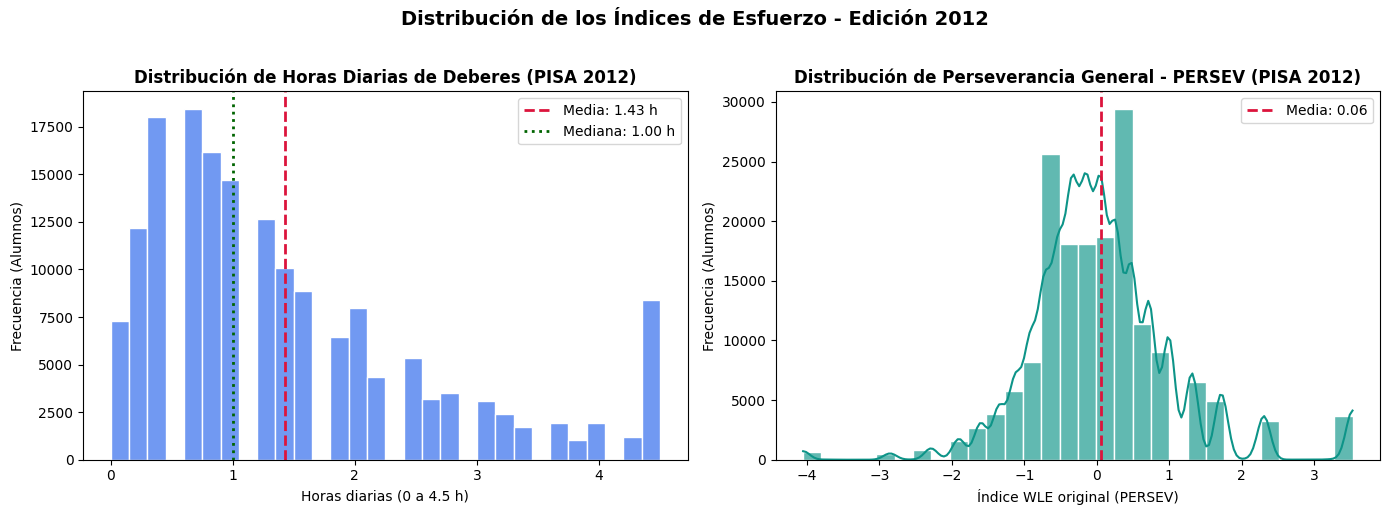

In [96]:
# Comprobación visual de los 2 índices extraídos en PISA 2012
serie_deb_2012 = df_base_2012_alumno['tiempo_deberes_totales_diarios'].dropna()
serie_pers_2012 = df_base_2012_alumno['perseverancia_bruta'].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    serie_deb_2012, kde=False, bins=30,
    color='#2563eb', edgecolor='white', alpha=0.65, ax=axes[0]
)
axes[0].axvline(serie_deb_2012.mean(), color='crimson', linestyle='--', linewidth=2, label=f'Media: {serie_deb_2012.mean():.2f} h')
axes[0].axvline(serie_deb_2012.median(), color='darkgreen', linestyle=':', linewidth=2, label=f'Mediana: {serie_deb_2012.median():.2f} h')
axes[0].set_title('Distribución de Horas Diarias de Deberes (PISA 2012)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Horas diarias (0 a 4.5 h)')
axes[0].set_ylabel('Frecuencia (Alumnos)')
axes[0].legend()

sns.histplot(
    serie_pers_2012, kde=True, bins=30,
    color='#0d9488', edgecolor='white', alpha=0.65, ax=axes[1]
)
axes[1].axvline(serie_pers_2012.mean(), color='crimson', linestyle='--', linewidth=2, label=f'Media: {serie_pers_2012.mean():.2f}')
axes[1].set_title('Distribución de Perseverancia General - PERSEV (PISA 2012)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Índice WLE original (PERSEV)')
axes[1].set_ylabel('Frecuencia (Alumnos)')
axes[1].legend()

plt.suptitle('Distribución de los Índices de Esfuerzo - Edición 2012', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 6.3 Obtención de datos equivalentes y cruce con estratos fijos en PISA 2015

### 6.3.1 Construcción del equivalente de Tiempo Total de Deberes y Perseverancia (`MOTIVAT`) en PISA 2015

En PISA 2015 la OCDE no preguntó por el tiempo de estudio global en una sola variable, sino que desglosó las horas semanales dedicadas a los deberes por materias. Para obtener la métrica equivalente al tiempo total diario, aplicamos una transformación matemática agregando los ítems del cuestionario del estudiante:

* **`ST071Q01NA`**: Horas semanales en Ciencias
* **`ST071Q02NA`**: Horas semanales en Matemáticas
* **`ST071Q03NA`**: Horas semanales en Lectura/Lengua

**Regla de codificación:**
Se calcula la suma horizontal de las horas reportadas para obtener el volumen semanal total, y se divide entre 5 (días lectivos) para estimar la carga diaria. Para evitar sesgos a la baja, la suma requiere un mínimo de una respuesta válida (`min_count=1`).

$$\text{tiempo\_deberes\_totales\_diarios} = \frac{\sum_{i=1}^{3} \text{ST071Q0}i\text{NA}}{5}$$

Para la **Perseverancia general**, extraemos el índice **`MOTIVAT`** (Batería `ST119` - Motivación de logro y superación académica) y cruzamos con `pisa2015_estratos_fijos.parquet`.

Comprobamos previamente qué se contempla en `OUTHOURS` contrastando la suma de las 5 materias frente a las 3 materias troncales. En **PISA 2022**, la propia OCDE acota el tiempo diario de deberes a un máximo de **4,5 horas/día**, mientras que en 2015 fijó un tope máximo (*top-coding*) de **70 horas semanales** para `OUTHOURS` en los microdatos.

In [99]:
# Carga de microdatos de estudiantes y estratos fijos para PISA 2015
ruta_est_2015 = RUTA_DATOS_ANUALES / 'pisa2015_estudiantes.parquet'
ruta_estratos_2015 = RUTA_ESTRATOS / 'pisa2015_estratos_fijos.parquet'

cols_5_materias = [f'ST071Q0{i}NA' for i in range(1, 6)]
cols_3_materias = ['ST071Q01NA', 'ST071Q02NA', 'ST071Q03NA']

cols_est_2015 = list(dict.fromkeys(
    claves_alumno + claves_colegio + columnas_pesos + cols_5_materias + ['OUTHOURS', 'MOTIVAT']
))

df_est_2015 = pd.read_parquet(ruta_est_2015, columns=cols_est_2015)
df_estratos_2015 = pd.read_parquet(ruta_estratos_2015)

In [100]:
# Cálculo de las tres variantes de tiempo en 2015 para la validación metodológica frente a OUTHOURS
df_est_2015['outhours_oficial'] = (df_est_2015['OUTHOURS'] / 5).clip(lower=0.0, upper=4.5)

df_est_2015['manual_5_materias'] = (
    df_est_2015[cols_5_materias].sum(axis=1, min_count=1) / 5
).clip(lower=0.0, upper=4.5)

df_est_2015['manual_3_materias'] = (
    df_est_2015[cols_3_materias].sum(axis=1, min_count=1) / 5
).clip(lower=0.0, upper=4.5)

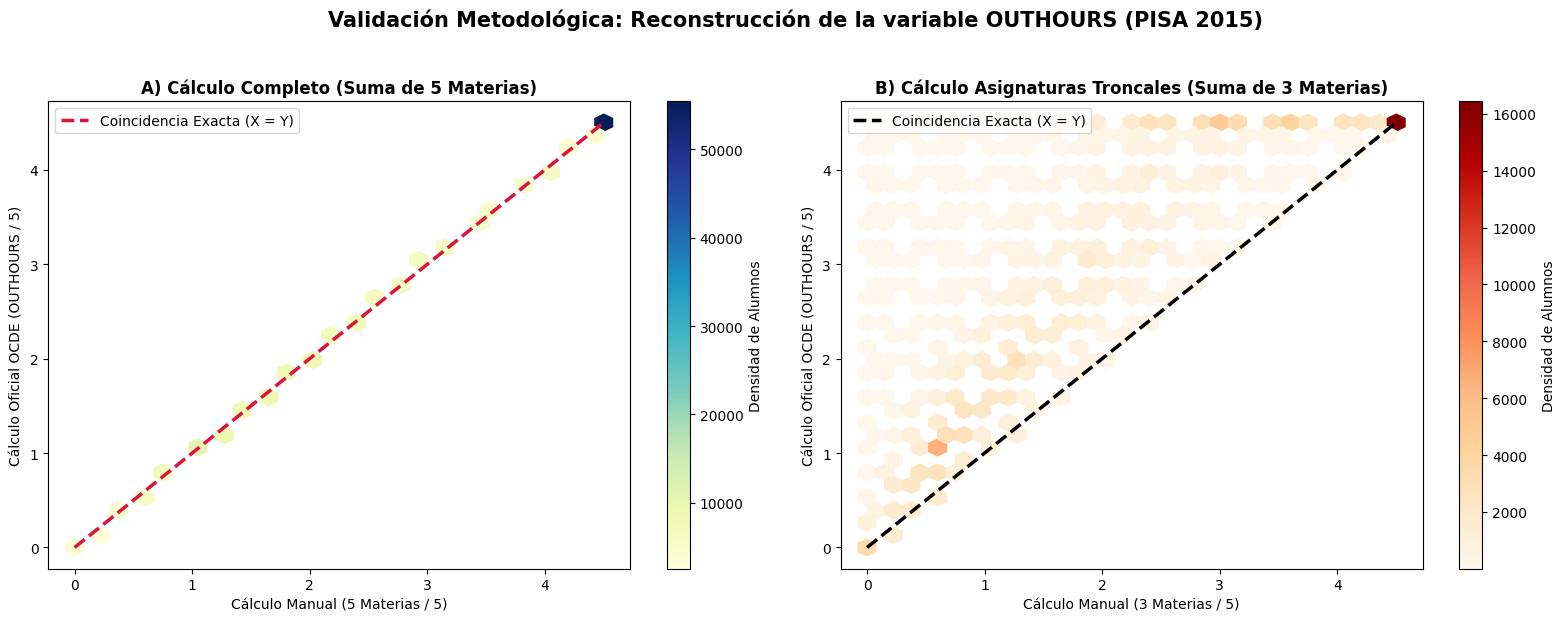

Correlación con 5 materias: 1.0000 (Ideal es 1.000)
Correlación con 3 materias: 0.8668


In [101]:
# Contraste visual Hexbin entre la reconstrucción con 5 materias y con las 3 materias troncales
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

hb1 = axes[0].hexbin(
    x=df_est_2015['manual_5_materias'], 
    y=df_est_2015['outhours_oficial'], 
    gridsize=30, cmap='YlGnBu', mincnt=1
)
axes[0].plot([0, 4.5], [0, 4.5], color='crimson', linestyle='--', linewidth=2.5, label='Coincidencia Exacta (X = Y)')
cb1 = fig.colorbar(hb1, ax=axes[0])
cb1.set_label('Densidad de Alumnos')
axes[0].set_title('A) Cálculo Completo (Suma de 5 Materias)', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Cálculo Manual (5 Materias / 5)')
axes[0].set_ylabel('Cálculo Oficial OCDE (OUTHOURS / 5)')
axes[0].legend()

hb2 = axes[1].hexbin(
    x=df_est_2015['manual_3_materias'], 
    y=df_est_2015['outhours_oficial'], 
    gridsize=30, cmap='OrRd', mincnt=1
)
axes[1].plot([0, 4.5], [0, 4.5], color='black', linestyle='--', linewidth=2.5, label='Coincidencia Exacta (X = Y)')
cb2 = fig.colorbar(hb2, ax=axes[1])
cb2.set_label('Densidad de Alumnos')
axes[1].set_title('B) Cálculo Asignaturas Troncales (Suma de 3 Materias)', fontweight='bold', fontsize=12)
axes[1].set_xlabel('Cálculo Manual (3 Materias / 5)')
axes[1].set_ylabel('Cálculo Oficial OCDE (OUTHOURS / 5)')
axes[1].legend()

plt.suptitle('Validación Metodológica: Reconstrucción de la variable OUTHOURS (PISA 2015)', fontsize=15, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

corr_5 = df_est_2015['manual_5_materias'].corr(df_est_2015['outhours_oficial'])
corr_3 = df_est_2015['manual_3_materias'].corr(df_est_2015['outhours_oficial'])
print(f"Correlación con 5 materias: {corr_5:.4f} (Ideal es 1.000)")
print(f"Correlación con 3 materias: {corr_3:.4f}")

<div style="background: linear-gradient(135deg, rgba(128, 128, 128, 0.25) 0%, rgba(64, 64, 64, 0.15) 100%); border-left: 5px solid rgba(128, 128, 128, 0.6); padding: 16px; border-radius: 8px; margin: 20px 0;">
  <strong style="display: block; margin-bottom: 6px; font-size: 1.1em;">
    Criterio de Selección: Suma de 3 Materias Troncales frente a OUTHOURS (2015)
  </strong>
  Aunque la suma de las 5 materias reproduce exactamente <code>OUTHOURS</code> (r = 1,0000), dentro de ese índice se acumulan horas de otras actividades y asignaturas no evaluadas del mismo modo en otros cuestionarios PISA, lo que dispara artificialmente el número de horas de deberes en 2015 frente a las demás ediciones (2012, 2018 y 2022). Por lo tanto, para garantizar la comparabilidad inter-edición, nos quedamos con la suma de los tres ítems relativos a las asignaturas troncales de PISA (<code>manual_3_materias</code>).
</div>

In [102]:
# Asignación de los 2 índices en 2015 y unión inner con los estratos fijos
df_est_2015['tiempo_deberes_totales_diarios'] = df_est_2015['manual_3_materias']
df_est_2015['perseverancia_bruta'] = df_est_2015['MOTIVAT']

df_base_2015_alumno = df_est_2015.merge(
    df_estratos_2015,
    on=claves_estrato_union, how='inner', validate='one_to_one'
)

df_base_2015_alumno['year'] = 2015
df_base_2015_alumno = df_base_2015_alumno[columnas_estandar_alumno].copy()

del df_est_2015, df_estratos_2015
gc.collect()

display(df_base_2015_alumno.head())
display(df_base_2015_alumno.shape)

,CNT,CNTSCHID,CNTSTUID,year,PERFIL_CODE,PERFIL_DESC,W_FSTUWT,SENWT,tiempo_deberes_totales_diarios,perseverancia_bruta
0,AUS,3600001,3610676,2015,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,28.20,0.55,0.80,0.59
1,AUS,3600001,3611874,2015,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,28.20,0.55,0.80,-0.48
2,AUS,3600001,3601769,2015,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,28.20,0.55,NaN,-0.28
3,AUS,3600001,3605996,2015,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,28.20,0.55,3.40,1.85
4,AUS,3600001,3608147,2015,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,33.45,0.65,0.60,-1.13


(178022, 10)

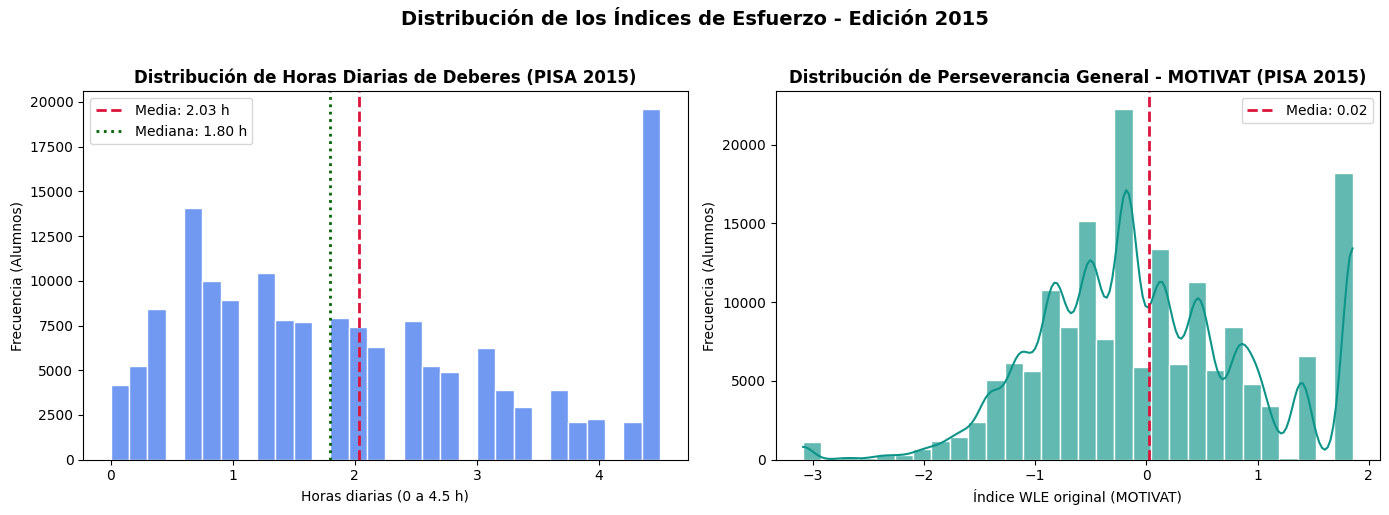

,tiempo_deberes_totales_diarios
count,159372.00
mean,2.03
std,1.37
min,0.00
25%,0.80
50%,1.80
75%,3.00
max,4.50


In [103]:
# Comprobación visual de los 2 índices extraídos en PISA 2015
serie_deb_2015 = df_base_2015_alumno['tiempo_deberes_totales_diarios'].dropna()
serie_pers_2015 = df_base_2015_alumno['perseverancia_bruta'].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    serie_deb_2015, kde=False, bins=30,
    color='#2563eb', edgecolor='white', alpha=0.65, ax=axes[0]
)
axes[0].axvline(serie_deb_2015.mean(), color='crimson', linestyle='--', linewidth=2, label=f'Media: {serie_deb_2015.mean():.2f} h')
axes[0].axvline(serie_deb_2015.median(), color='darkgreen', linestyle=':', linewidth=2, label=f'Mediana: {serie_deb_2015.median():.2f} h')
axes[0].set_title('Distribución de Horas Diarias de Deberes (PISA 2015)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Horas diarias (0 a 4.5 h)')
axes[0].set_ylabel('Frecuencia (Alumnos)')
axes[0].legend()

sns.histplot(
    serie_pers_2015, kde=True, bins=30,
    color='#0d9488', edgecolor='white', alpha=0.65, ax=axes[1]
)
axes[1].axvline(serie_pers_2015.mean(), color='crimson', linestyle='--', linewidth=2, label=f'Media: {serie_pers_2015.mean():.2f}')
axes[1].set_title('Distribución de Perseverancia General - MOTIVAT (PISA 2015)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Índice WLE original (MOTIVAT)')
axes[1].set_ylabel('Frecuencia (Alumnos)')
axes[1].legend()

plt.suptitle('Distribución de los Índices de Esfuerzo - Edición 2015', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

display(df_base_2015_alumno['tiempo_deberes_totales_diarios'].describe().to_frame())

* El valor `4,5` actúa como categoría superior acotada (*top-coded category*, equivalente a **"4,5 horas o más al día"**) tal como se establece en PISA 2022, preservando en la muestra a los estudiantes de alta dedicación sin distorsionar la escala con valores extremos atípicos.

## 6.4 Obtención de datos equivalentes y cruce con estratos fijos en PISA 2018

### 6.4.1 Construcción del equivalente de Tiempo Total de Deberes y Perseverancia (`WORKMAST`) en PISA 2018

En PISA 2018, la información sobre el tiempo de estudio en casa se extrae del Cuestionario de Trayectoria Educativa (*Educational Career*), evaluando el tiempo dedicado después de volver del colegio (`EC159Q01HA` para horas y `EC159Q02HA` para minutos) y aplicando un límite superior de **4,5 horas** para mantener la misma cota que en 2012, 2015 y 2022.

Para la **Perseverancia general**, extraemos el índice **`WORKMAST`** (Batería `ST182` - Motivación por dominar tareas y esfuerzo constante) y cruzamos con `pisa2018_estratos_fijos.parquet`.

In [104]:
# Carga de microdatos de estudiantes y estratos fijos para PISA 2018
ruta_est_2018 = RUTA_DATOS_ANUALES / 'pisa2018_estudiantes.parquet'
ruta_estratos_2018 = RUTA_ESTRATOS / 'pisa2018_estratos_fijos.parquet'

cols_est_2018 = list(dict.fromkeys(
    claves_alumno + claves_colegio + columnas_pesos + ['EC158Q01HA', 'EC158Q02HA', 'EC159Q01HA', 'EC159Q02HA', 'WORKMAST']
))
df_est_2018 = pd.read_parquet(ruta_est_2018, columns=cols_est_2018)
df_estratos_2018 = pd.read_parquet(ruta_estratos_2018)

In [105]:
# Funciones de limpieza para la escala desplazada de horas y minutos del cuestionario ECQ en PISA 2018
def limpiar_horas_ec(serie_horas):
    condiciones = [
        serie_horas.between(1, 9),
        serie_horas == 11
    ]
    valores = [
        serie_horas - 1,
        0.0
    ]
    resultado = np.select(condiciones, valores, default=np.nan)
    return pd.Series(resultado, index=serie_horas.index)

def limpiar_minutos_ec(serie_minutos):
    condiciones = [
        serie_minutos.between(1, 12),
        serie_minutos == 14
    ]
    valores = [
        (serie_minutos - 1) * 5.0,  
        0.0
    ]
    resultado = np.select(condiciones, valores, default=np.nan)
    return pd.Series(resultado, index=serie_minutos.index)

# Cálculo del bloque de estudio vespertino tras el colegio y acotación superior a 4.5 horas
h_tarde = limpiar_horas_ec(df_est_2018['EC159Q01HA'])
m_tarde = limpiar_minutos_ec(df_est_2018['EC159Q02HA']) / 60.0
t_tarde = h_tarde.add(m_tarde, fill_value=0)

df_est_2018['tiempo_deberes_totales_diarios'] = (
    pd.concat([t_tarde], axis=1)
    .sum(axis=1, min_count=1)
    .clip(upper=4.5)
)
df_est_2018['perseverancia_bruta'] = df_est_2018['WORKMAST']

# Unión inner con los estratos fijos de PISA 2018
df_base_2018_alumno = df_est_2018.merge(
    df_estratos_2018,
    on=claves_estrato_union, how='inner', validate='one_to_one'
)
df_base_2018_alumno['year'] = 2018
df_base_2018_alumno = df_base_2018_alumno[columnas_estandar_alumno].copy()

del df_est_2018, df_estratos_2018
gc.collect()

display(df_base_2018_alumno.head())
display(df_base_2018_alumno.shape)

,CNT,CNTSCHID,CNTSTUID,year,PERFIL_CODE,PERFIL_DESC,W_FSTUWT,SENWT,tiempo_deberes_totales_diarios,perseverancia_bruta
0,AUS,3600072,3600002,2018,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,19.40,0.38,2.33,-0.10
1,AUS,3600122,3600003,2018,PUB_URB_MED,Público | Urbano | Instituto Mediano,5.66,0.11,NaN,-0.10
2,AUS,3600385,3600005,2018,PUB_URB_MED,Público | Urbano | Instituto Mediano,48.76,0.95,0.00,-0.71
3,AUS,3600758,3600006,2018,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,21.39,0.41,1.00,-0.10
4,AUS,3600474,3600011,2018,PUB_URB_MACRO,Público | Urbano | Macro-Instituto,30.34,0.59,3.50,-0.65


(189532, 10)

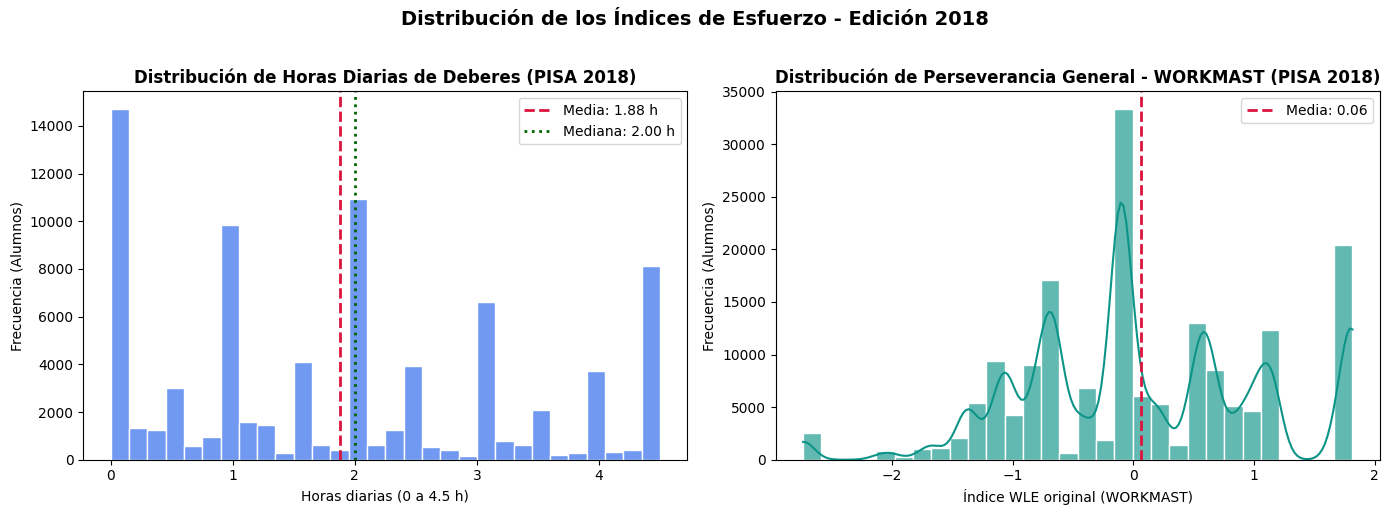

In [106]:
# Comprobación visual de los 2 índices extraídos en PISA 2018
serie_deb_2018 = df_base_2018_alumno['tiempo_deberes_totales_diarios'].dropna()
serie_pers_2018 = df_base_2018_alumno['perseverancia_bruta'].dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    serie_deb_2018, kde=False, bins=30,
    color='#2563eb', edgecolor='white', alpha=0.65, ax=axes[0]
)
axes[0].axvline(serie_deb_2018.mean(), color='crimson', linestyle='--', linewidth=2, label=f'Media: {serie_deb_2018.mean():.2f} h')
axes[0].axvline(serie_deb_2018.median(), color='darkgreen', linestyle=':', linewidth=2, label=f'Mediana: {serie_deb_2018.median():.2f} h')
axes[0].set_title('Distribución de Horas Diarias de Deberes (PISA 2018)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Horas diarias (0 a 4.5 h)')
axes[0].set_ylabel('Frecuencia (Alumnos)')
axes[0].legend()

sns.histplot(
    serie_pers_2018, kde=True, bins=30,
    color='#0d9488', edgecolor='white', alpha=0.65, ax=axes[1]
)
axes[1].axvline(serie_pers_2018.mean(), color='crimson', linestyle='--', linewidth=2, label=f'Media: {serie_pers_2018.mean():.2f}')
axes[1].set_title('Distribución de Perseverancia General - WORKMAST (PISA 2018)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Índice WLE original (WORKMAST)')
axes[1].set_ylabel('Frecuencia (Alumnos)')
axes[1].legend()

plt.suptitle('Distribución de los Índices de Esfuerzo - Edición 2018', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# 7. Estandarización Z-Score Intra-Anual y Tabla Final para el Modelo (2012–2022)

## 7.1 Justificación psicométrica del Z-Score intra-anual para el índice de perseverancia

¿Por qué no podemos estimar nuestros propios índices psicométricos con origen común para el esfuerzo —como sí se hace en la dimensión de posesiones materiales para los recursos del hogar— y resulta imprescindible aplicar el **Z-Score intra-anual**?

1. **Ausencia de ítems puente idénticos y cambio en los parámetros de dificultad ($\beta_j$):**
   * Como las preguntas del cuestionario de actitudes cambian de una década a otra (los ítems de la batería `ST307` en 2022 no son idénticos a los de `ST182` en 2018, `ST119` en 2015 o `ST93` en 2012), la calibración psicométrica mediante Teoría de Respuesta al Ítem (IRT) **no comparte los mismos parámetros de dificultad de ítem ($\beta_j$)**.
   * Por lo tanto, incluso si estimáramos nuestros propios índices IRT edición por edición, la escala latente $\theta_i$ estimada para 2012 (`PERSEV`) no tendría el mismo origen absoluto ni la misma métrica de intervalo que la de 2022 (`PERSEVAGR`). En psicometría, esta unión de escalas WLE análogas se denomina **Armonización Conceptual de Constructos *Proxies***, y no una escala de tendencia (*trend scale*) anclada.

2. **Necesidad del Z-Score intra-anual (`groupby('year')`) para el panel combinado (*pooled panel*):**
   * Además, aunque los índices WLE originales de la OCDE se publican con media $0$ y desviación típica $1$ para el total internacional de cada ciclo, al cruzar los alumnos con los **estratos fijos válidos** de nuestra muestra de países, la media empírica de cada edición puede desplazarse ligeramente.
   * Por consiguiente, para concatenar las cuatro olas en nuestro *pooled panel* (2012–2022) e introducirlas sin sesgo de cohorte en el modelo **XGBoost**, aplicamos el **Z-Score intra-anual (`groupby('year')`)**:

$$Z_{i, t} = \frac{\theta_{i, t} - \mu_t}{\sigma_t} \quad \forall t \in \{2012, 2015, 2018, 2022\}$$

De este modo, la columna unificada **`esfuerzo_perseverancia_zscore`** (y su alias `esfuerzo_perseverancia_alumno`) sitúa a cada estudiante en una **escala de posición relativa intra-cohorte** ($\mu_t = 0, \sigma_t = 1$), plenamente comparable entre ediciones. Asimismo, conservamos en la tabla final tanto el tiempo de deberes en horas reales (`tiempo_deberes_totales_diarios`) como su versión estandarizada (`tiempo_deberes_zscore`) y la perseverancia original (`perseverancia_bruta`).

## 7.2 Concatenación del panel (2012–2022), cálculo de Z-Score y exportación

In [107]:
# Concatenación de las cuatro ediciones armonizadas y cruzadas con los estratos fijos
df_esfuerzo_panel_alumno = pd.concat(
    [df_base_2012_alumno, df_base_2015_alumno, df_base_2018_alumno, df_base_2022_alumno],
    ignore_index=True
)

del df_base_2012_alumno, df_base_2015_alumno, df_base_2018_alumno, df_base_2022_alumno
gc.collect()

# Aplicación de la estandarización Z-Score intra-anual (groupby('year')) para perseverancia y tiempo de deberes
df_esfuerzo_panel_alumno['esfuerzo_perseverancia_zscore'] = (
    df_esfuerzo_panel_alumno.groupby('year')['perseverancia_bruta']
    .transform(lambda s: (s - s.mean()) / s.std())
)
df_esfuerzo_panel_alumno['tiempo_deberes_zscore'] = (
    df_esfuerzo_panel_alumno.groupby('year')['tiempo_deberes_totales_diarios']
    .transform(lambda s: (s - s.mean()) / s.std())
)
df_esfuerzo_panel_alumno['esfuerzo_perseverancia_alumno'] = df_esfuerzo_panel_alumno['esfuerzo_perseverancia_zscore']

# Vista agregada a nivel de país para la auditoría longitudinal de cobertura
df_medias_pais_historico = pd.read_parquet(
    RUTA_ASIGNATURAS / 'pisa_medias_asignaturas_pais_anual.parquet',
    columns=['CNT', 'year', 'media_math_pais']
)

df_indicadores_pais_historico = promedio_ponderado_indicadores_agrupado(
    df_esfuerzo_panel_alumno,
    ['tiempo_deberes_totales_diarios', 'esfuerzo_perseverancia_zscore'],
    'W_FSTUWT',
    ['CNT', 'year']
)

df_esfuerzo_panel_pais = df_medias_pais_historico.merge(
    df_indicadores_pais_historico, on=['CNT', 'year'], how='inner', validate='one_to_one'
)

print(f"Panel longitudinal de esfuerzo + estrato fijo a nivel ALUMNO: {len(df_esfuerzo_panel_alumno):,} filas")
display(df_esfuerzo_panel_alumno.head(10))

Panel longitudinal de esfuerzo + estrato fijo a nivel ALUMNO: 819,468 filas


,CNT,CNTSCHID,CNTSTUID,year,PERFIL_CODE,PERFIL_DESC,W_FSTUWT,SENWT,tiempo_deberes_totales_diarios,perseverancia_bruta,esfuerzo_perseverancia_zscore,tiempo_deberes_zscore,esfuerzo_perseverancia_alumno
0,AUS,0000001,00001,2012,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,33.39,0.67,1.20,NaN,NaN,-0.19,NaN
1,AUS,0000001,00002,2012,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,33.39,0.67,1.00,NaN,NaN,-0.37,NaN
2,AUS,0000001,00003,2012,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,33.39,0.67,4.50,0.26,0.20,2.62,0.20
3,AUS,0000001,00004,2012,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,35.22,0.70,1.80,0.48,0.42,0.32,0.42
4,AUS,0000001,00005,2012,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,35.22,0.70,2.20,NaN,NaN,0.66,NaN
5,AUS,0000001,00006,2012,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,33.39,0.67,NaN,1.72,1.66,NaN,1.66
6,AUS,0000001,00007,2012,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,33.39,0.67,NaN,1.31,1.25,NaN,1.25
7,AUS,0000001,00008,2012,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,35.22,0.70,NaN,0.72,0.66,NaN,0.66
8,AUS,0000001,00009,2012,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,35.22,0.70,NaN,0.72,0.66,NaN,0.66
9,AUS,0000001,00010,2012,PRI_URB_MACRO,Privado | Urbano | Macro-Instituto,35.22,0.70,1.20,NaN,NaN,-0.19,NaN


In [108]:
# Exportación de la tabla consolidada final a Parquet lista para alimentar el modelo general
ruta_salida_esfuerzo = RUTA_INTERMEDIOS / 'pisa_esfuerzo_alumno_anual.parquet'
df_esfuerzo_panel_alumno.to_parquet(ruta_salida_esfuerzo, index=False)
print(f"Archivo exportado correctamente: {ruta_salida_esfuerzo.as_posix()} ({len(df_esfuerzo_panel_alumno):,} registros)")

Archivo exportado correctamente: ../../data/intermediate/pisa_esfuerzo_alumno_anual.parquet (819,468 registros)


## 7.3 Auditoría final de datos faltantes y distribuciones por edición (2012–2022)

Cuantificamos el volumen final de estudiantes con estrato fijo asignado y el porcentaje de valores faltantes (`NaN`) en cada uno de los 2 índices definitivos (`tiempo_deberes_totales_diarios` y `esfuerzo_perseverancia_zscore`) a través de las cuatro ediciones, verificando que la estandarización intra-anual centre perfectamente la escala de perseverancia en $\mu = 0$ y $\sigma = 1$ en todos los ciclos.

Cobertura y Datos Faltantes (Missingness) por Edición PISA (2012-2022):


,year,Alumnos_Estrato_Fijo,Colegios_Unicos,Paises_Retenidos,Alumnos_con_Deberes,NaN_Deberes_pct,Alumnos_con_Perseverancia,NaN_Perseverancia_pct
0,2012,265820,1445,32,171035,35.66,172832,34.98
1,2015,178022,6841,28,159372,10.48,172743,2.97
2,2018,189532,7346,26,81111,57.20,172714,8.87
3,2022,186094,6987,25,170527,8.37,164134,11.80


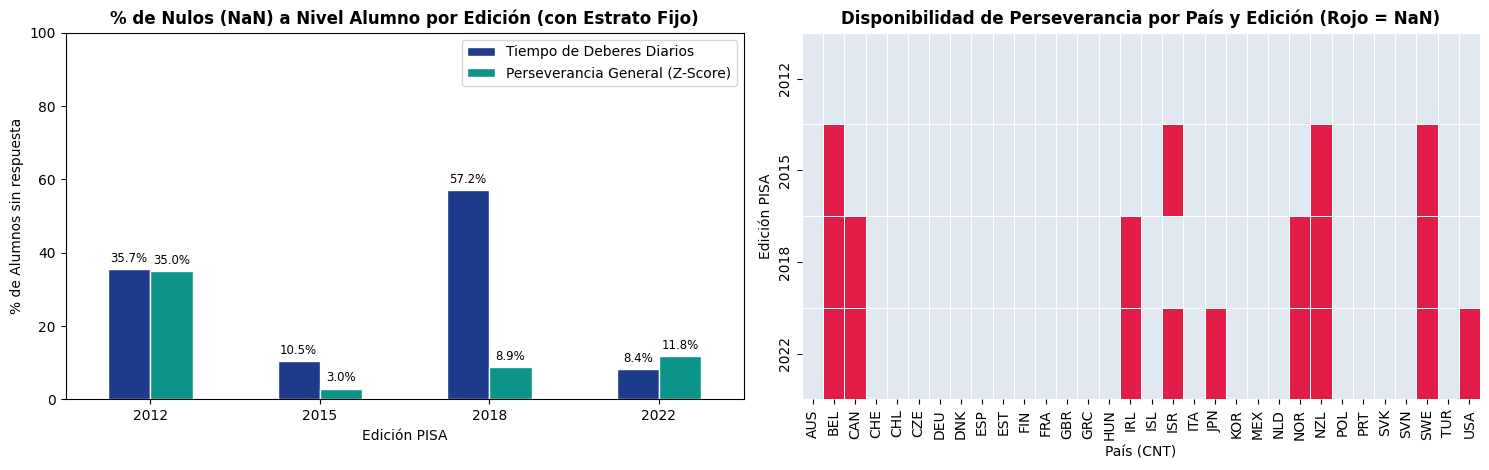

In [109]:
# Auditoría de cobertura y porcentaje de valores faltantes (NaN) por edición en los 2 índices finales
resumen_nulos_edicion = (
    df_esfuerzo_panel_alumno.groupby('year')
    .agg(
        Alumnos_Estrato_Fijo=('CNTSTUID', 'count'),
        Colegios_Unicos=('CNTSCHID', 'nunique'),
        Paises_Retenidos=('CNT', 'nunique'),
        Alumnos_con_Deberes=('tiempo_deberes_totales_diarios', 'count'),
        NaN_Deberes_pct=('tiempo_deberes_totales_diarios', lambda s: (s.isna().mean() * 100).round(2)),
        Alumnos_con_Perseverancia=('esfuerzo_perseverancia_zscore', 'count'),
        NaN_Perseverancia_pct=('esfuerzo_perseverancia_zscore', lambda s: (s.isna().mean() * 100).round(2))
    )
    .reset_index()
)

print("Cobertura y Datos Faltantes (Missingness) por Edición PISA (2012-2022):")
display(resumen_nulos_edicion)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

resumen_nulos_edicion.set_index('year')[['NaN_Deberes_pct', 'NaN_Perseverancia_pct']].plot(
    kind='bar', ax=axes[0], color=['#1e3a8a', '#0d9488'], edgecolor='white', rot=0
)
axes[0].set_title('% de Nulos (NaN) a Nivel Alumno por Edición (con Estrato Fijo)', fontweight='bold')
axes[0].set_ylabel('% de Alumnos sin respuesta')
axes[0].set_xlabel('Edición PISA')
axes[0].set_ylim(0, 100)
axes[0].legend(['Tiempo de Deberes Diarios', 'Perseverancia General (Z-Score)'])
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.1f%%', padding=3, fontsize=8.5)

pivot_missing_pais = df_esfuerzo_panel_pais.pivot(
    index='year', columns='CNT', values='esfuerzo_perseverancia_zscore'
).isna()

sns.heatmap(
    pivot_missing_pais, cmap=['#e2e8f0', '#e11d48'], cbar=False,
    linewidths=0.5, linecolor='white', ax=axes[1]
)
axes[1].set_title('Disponibilidad de Perseverancia por País y Edición (Rojo = NaN)', fontweight='bold')
axes[1].set_xlabel('País (CNT)')
axes[1].set_ylabel('Edición PISA')

plt.tight_layout()
plt.show()

Resumen estadístico de los 2 índices de esfuerzo a Nivel Alumno (2012-2022):


tiempo_deberes_totales_diarios                             \
                              count mean  std  min median  max   
year                                                             
2012                         171035 1.43 1.17 0.00   1.00 4.50   
2015                         159372 2.03 1.37 0.00   1.80 4.50   
2018                          81111 1.88 1.46 0.00   2.00 4.50   
2022                         170527 1.54 1.24 0.25   1.50 4.50   

     tiempo_deberes_zscore                   ... perseverancia_bruta        \
                     count  mean  std   min  ...                 std   min   
year                                         ...                             
2012                171035  0.00 1.00 -1.22  ...                1.00 -4.05   
2015                159372  0.00 1.00 -1.48  ...                0.99 -3.09   
2018                 81111 -0.00 1.00 -1.28  ...                1.00 -2.74   
2022                170527 -0.00 1.00 -1.04  ...                1.00 -6.00   

                 esfuerzo_perseverancia_zscore                               
     median  max                         count  mean  std   min median  max  
year                                                                         
2012   0.05 3.53                        172832  0.00 1.00 -4.10  -0.00 3.47  
2015  -0.17 1.85                        172743  0.00 1.00 -3.14  -0.19 1.85  
2018  -0.10 1.82                        172714 -0.00 1.00 -2.80  -0.16 1.76  
2022  -0.13 4.89                        164134 -0.00 1.00 -6.03  -0.14 4.90  

[4 rows x 24 columns]

C:\Users\victo\AppData\Local\Temp\ipykernel_49252\913605144.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
C:\Users\victo\AppData\Local\Temp\ipykernel_49252\913605144.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


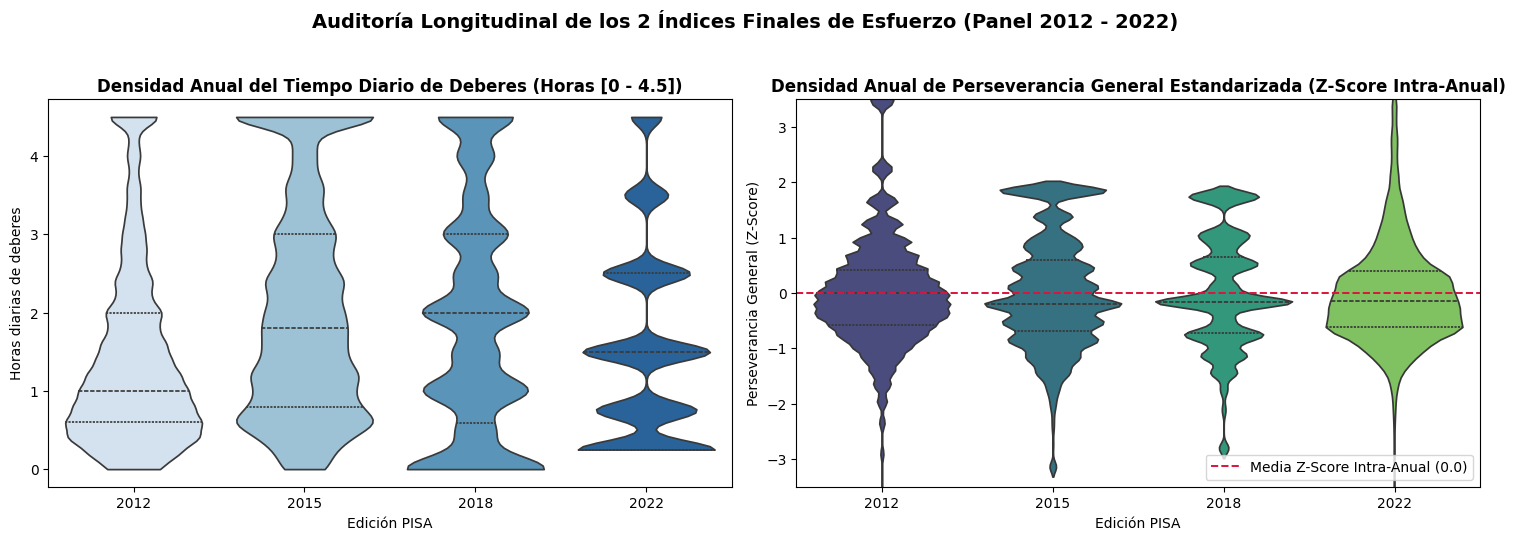

In [110]:
# Verificación estadística de escalas (originales y Z-Score intra-anual) y violines longitudinales
print("Resumen estadístico de los 2 índices de esfuerzo a Nivel Alumno (2012-2022):")

columnas_auditoria = [
    'tiempo_deberes_totales_diarios',
    'tiempo_deberes_zscore',
    'perseverancia_bruta',
    'esfuerzo_perseverancia_zscore'
]

resumen_panel = (
    df_esfuerzo_panel_alumno.groupby('year')[columnas_auditoria]
    .agg(['count', 'mean', 'std', 'min', 'median', 'max'])
    .round(2)
)
display(resumen_panel)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))

sns.violinplot(
    data=df_esfuerzo_panel_alumno, 
    x='year', 
    y='tiempo_deberes_totales_diarios', 
    palette='Blues', 
    inner='quartile',
    cut=0,
    ax=axes[0]
)
axes[0].set_title('Densidad Anual del Tiempo Diario de Deberes (Horas [0 - 4.5])', fontweight='bold')
axes[0].set_xlabel('Edición PISA')
axes[0].set_ylabel('Horas diarias de deberes')

sns.violinplot(
    data=df_esfuerzo_panel_alumno, 
    x='year', 
    y='esfuerzo_perseverancia_zscore', 
    palette='viridis', 
    inner='quartile',
    ax=axes[1]
)
axes[1].axhline(0.0, color='crimson', linestyle='--', linewidth=1.4, label='Media Z-Score Intra-Anual (0.0)')
axes[1].set_ylim(-3.5, 3.5)
axes[1].set_title('Densidad Anual de Perseverancia General Estandarizada (Z-Score Intra-Anual)', fontweight='bold')
axes[1].set_xlabel('Edición PISA')
axes[1].set_ylabel('Perseverancia General (Z-Score)')
axes[1].legend(loc='lower right')

plt.suptitle('Auditoría Longitudinal de los 2 Índices Finales de Esfuerzo (Panel 2012 - 2022)', fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

**Conclusiones finales de la auditoría longitudinal (2012–2022):**
* **Alineación exacta tras la estandarización intra-anual:** La tabla de resumen confirma que `esfuerzo_perseverancia_zscore` (y `tiempo_deberes_zscore`) presenta exactamente media **$0,00$** y desviación típica **$1,00$** dentro de cada una de las cuatro ediciones (`2012`, `2015`, `2018` y `2022`), corrigiendo las diferencias de origen psicométrico entre `PERSEV`, `MOTIVAT`, `WORKMAST` y `PERSEVAGR`.
* **Integración con los estratos fijos:** Los **$819.468$ alumnos** del panel consolidado (`pisa_esfuerzo_alumno_anual.parquet`) cuentan con su identificador único (`CNT`, `CNTSCHID`, `CNTSTUID`, `year`), su estrato fijo institucional (`PERFIL_CODE` y `PERFIL_DESC`) y sus 2 índices de esfuerzo depurados, quedando listos para su unión con la tabla de recursos familiares y el modelado final.